<p align="center">
  <img src="assets/hero_proje.svg" width="100%" alt="Gün 55 — Müşteri takımyıldızları: K-Means ve 28 algoritma">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-55-1B1446?style=for-the-badge" alt="Gün 55">
  <img src="https://img.shields.io/badge/Konu-K--Means_(Proje)-FBBF24?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7_%E2%86%92_Orta-16A34A?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/Veri-Customer_Personality_(Kaggle)-38BDF8?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Algoritma-28_%2B_taban-F472B6?style=for-the-badge" alt="Algoritma">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🛒</h3><b>2.240 müşteri</b><br><br>Gelir, aile, sepet ve kanal<br>bilgisi; <b>segment etiketi yok</b><br><br></td><td width="25%" valign="top" align="center"><h3>🏁</h3><b>28 algoritma</b><br><br>Merkez, hiyerarşi, olasılık,<br>yoğunluk ve graf aileleri<br><br></td><td width="25%" valign="top" align="center"><h3>🧪</h3><b>Dürüst ölçüm</b><br><br>3 iç ölçüt + kararlılık +<br><b>kilitli test</b> + dış doğrulama<br><br></td><td width="25%" valign="top" align="center"><h3>🎯</h3><b>Pazarlama kararı</b><br><br>Kime, hangi kanaldan,<br><b>kâra geçiş eşiğiyle</b><br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🛒 Gerçek bir **Kaggle** müşteri verisiyle **uçtan uca** bir segmentasyon projesi kurmak
- 🧼 Kopya müşteri, uç değer ve eksik geliri **karar defteriyle** ele almak
- 🔒 Etiketsiz bir problemde bile **test setini kilitlemek** ve ön işlemeyi **sızıntısız** boru hattına koymak
- 🦵 Segment sayısını **beş ölçüt** ve **önceden yazılmış bir kuralla** seçmek
- 🏁 **28 kümeleme algoritmasını** (+ rastgele taban) aynı müşteriler, aynı ölçütler ve **uygunluk şartlarıyla** yarıştırmak
- 📊 **Kararlılığı** (bootstrap, tohum) ve **genellemeyi** (test) ölçmek; "silüet tuzağına" düşmemek
- 🧭 Segmentleri **iş diliyle** adlandırmak, vekil karar ağacıyla **kurala** çevirmek
- 💶 Kümelemede **hiç kullanılmayan** kampanya yanıtıyla **dış doğrulama** yapmak, kâra geçiş eşiğine göre hedefleme önermek
- ⚖️ Hassas özellikler ve sınırdaki müşteriler için **adalet ve hata** denetimi yapmak; modeli kaydedip **ayrı süreçte** test etmek

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_proje.svg" width="100%" alt="Proje yol haritası: 16 bölüm">
</p>

### 🧭 Hızlı Erişim

| # | Bölüm | Ana soru |
|:-:|:--|:--|
| 1 | [Kurulum](#p1) | Hangi araçlar, hangi tohum? |
| 2 | [Senaryo, veri, ölçütler](#p2) | İş sorusu ne, başarıyı etiketsiz nasıl ölçeriz? |
| 3 | [Veri kalitesi](#p3) | Kopya, uç değer, eksik, tuhaf kategori var mı? |
| 4 | [Dürüst bölme](#p4) | Test seti neden kilitli? |
| 5 | [Keşif](#p5) | Müşteriler nasıl dağılıyor? |
| 6 | [Ön işleme deneyi](#p6) | Ölçek ve log, segmentleri nasıl değiştirir? |
| 7 | [Kaç segment?](#p7) | Beş ölçüt ve önceden yazılmış kural ne diyor? |
| 8 | [Büyük yarış](#p8) | 28 algoritma + taban, hangisi uygun ve iyi? |
| 9 | [Kararlılık](#p9) | Sonuç tesadüf mü? |
| 10 | [Ayar](#p10) | Düğmeleri çevirince ne kazanırız? |
| 11 | [Segment profili](#p11) | Bu müşteriler kim, hangi kurallarla ayrılıyor? |
| 12 | [Test seti](#p12) | Segmentler yeni müşteride de var mı? |
| 13 | [İş analizi](#p13) | Kime kampanya yapalım, kâr eder mi? |
| 14 | [Adalet ve hata](#p14) | Hassas gruplar, sınırdakiler, sıra dışılar |
| 15 | [Kayıt](#p15) | Model işletmede nasıl kullanılır? |
| 16 | [Özet](#p16) | Sayılar, yönetici özeti, quiz, kaynakça |

<a id="p1"></a>

<p align="center">
  <img src="assets/proje_01.svg" width="100%" alt="Bölüm 1: Kurulum">
</p>

Kütüphaneleri, tohumu, renkleri ve yardımcı işlevleri tek hücrede topluyoruz. Tüm rastgelelik **`RANDOM_STATE = 42`** ile sabitlenir. Elle yazılmış kümeleyiciler (K-Medoids, K-Medyan, Bulanık C-Ortalamalar, rastgele taban) `musteri_yardimci.py` içindedir; böylece kaydedilen model başka bir süreçte de yüklenebilir.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, time, json, warnings, subprocess, sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy, joblib
from scipy import stats
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors, kneighbors_graph
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.cluster import (KMeans, MiniBatchKMeans, BisectingKMeans, AgglomerativeClustering, Birch, SpectralClustering,
                             MeanShift, estimate_bandwidth, DBSCAN, HDBSCAN, OPTICS, AffinityPropagation)
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, pairwise_distances)

from musteri_yardimci import (veri_oku, ozellik_uret, log1p_donustur, KUME_OZELLIKLERI, LOG_SUTUNLARI, URUN_TR,
                              KMedoids, KMedyan, BulanikCOrtalama, RastgeleTaban, segment_ata)

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
RANDOM_STATE = 42; RS = RANDOM_STATE
N_JOBS = min(4, os.cpu_count() or 1)
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = Path("outputs/reports"); REP_DIR.mkdir(parents=True, exist_ok=True)

RENK = {"altin": "#E5A100", "mavi": "#2B6CB0", "pembe": "#D1495B", "yesil": "#2E9E6B", "mor": "#6C5CE7",
        "turuncu": "#E8833A", "cyan": "#0E9AA7", "gri": "#8A94A6", "koyu": "#1F2A44"}
KUME_RENK = ["#E5A100", "#2B6CB0", "#D1495B", "#2E9E6B", "#6C5CE7", "#E8833A", "#0E9AA7", "#8D6E63", "#5C6BC0", "#AD1457"]
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.25})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG_DIR / f"{ad}.png"); print(f"💾 Kaydedildi → outputs/figures/{ad}.png")


def gif_kaydet(kare_ciz, n_kare, ad, figsize=(8, 4.6), fps=3):
    """kare_ciz(i, fig) ile animasyon üretir, GIF olarak kaydeder ve gösterir."""
    fig = plt.figure(figsize=figsize)
    def guncelle(i):
        fig.clear(); kare_ciz(i, fig); return []
    anim = FuncAnimation(fig, guncelle, frames=n_kare, blit=False)
    yol = FIG_DIR / f"{ad}.gif"; anim.save(yol, writer=PillowWriter(fps=fps), dpi=80); plt.close(fig)
    print(f"🎞️ Animasyon → {yol}"); display(Image(filename=str(yol)))


def rapor_kaydet(df, ad, index=True):
    """Tabloyu outputs/reports altına CSV olarak yazar."""
    df.to_csv(REP_DIR / f"{ad}.csv", index=index, encoding="utf-8-sig"); print(f"📄 Rapor → outputs/reports/{ad}.csv")


def wilson(k, n, z=1.96):
    """Bir oranın Wilson %95 güven aralığı (küçük gruplarda normal yaklaşımdan daha güvenilir)."""
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z ** 2 / n; m = (p + z ** 2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return (m - h, m + h)


def cramers_v(a, b):
    """İki kategorik değişken arasındaki ilişki gücü (0 = ilişkisiz, 1 = tam ilişki)."""
    t = pd.crosstab(a, b)
    if min(t.shape) < 2: return 0.0
    chi2 = stats.chi2_contingency(t, correction=False)[0]; n = t.to_numpy().sum()
    return float(np.sqrt(chi2 / (n * (min(t.shape) - 1))))

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| işçi:", N_JOBS)

Python 3.13.18 | scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.5 | işçi: 4


<a id="p2"></a>

<p align="center">
  <img src="assets/proje_02.svg" width="100%" alt="Bölüm 2: Senaryo ve veri">
</p>


### 🎯 2.1 · Senaryo

Bir **gıda ve market zinciri** (veri, Brezilyalı iFood şirketinin veri analisti vaka çalışmasından gelir), sadakat programındaki müşterilerine yeni bir kampanya hazırlıyor. Son pilot kampanya **zarar etti**: herkese aynı mesaj gönderildi, yalnızca küçük bir kısmı yanıt verdi.

**İş sorusu:** *Müşterileri gelir, aile yapısı ve alışveriş davranışına göre **birbirine benzeyen gruplara (segmentlere)** ayırabilir miyiz? Bu segmentler kampanyaya farklı yanıt veriyor mu, ve hangi segmente hangi kanaldan ulaşmalıyız?*

### 🛒 2.2 · Veri

**Kaggle "Customer Personality Analysis"** (Patel, 2021): 2.240 müşteri, 29 sütun. Sütunlar dört gruba ayrılır:

| Grup | Sütunlar (örnek) | Bu projedeki rolü |
|:--|:--|:--|
| 👤 Kişi | Doğum yılı, eğitim, medeni durum, gelir, evdeki çocuk/ergen sayısı, kayıt tarihi | Gelir, yaş, çocuk → **kümeleme**; eğitim, medeni durum → yalnızca **adalet denetimi** |
| 🧺 Ürün | Son 2 yılda şarap, meyve, et, balık, tatlı, altın harcaması | Toplam harcama → **kümeleme**; ürün payları → **profil** |
| 🛍️ Kanal | Web, katalog, mağaza alışverişi; indirimli alışveriş; aylık web ziyareti | Alışveriş sayısı, indirim oranı, web ziyareti → **kümeleme**; kanal payları → **profil** |
| 📣 Kampanya | 5 eski kampanyayı kabul etti mi, **son kampanyaya yanıt (Response)**, şikâyet | **Kümelemede kullanılmaz** → yalnızca **dış doğrulama ve iş analizi** |

> Çalışma ortamında Kaggle'a doğrudan erişim kapalıydı. Aynı içerik **iki bağımsız GitHub aynasından** indirildi; iki dosyanın **hücre hücre aynı** olduğu ve Kaggle sayfasındaki boyutla (2.240 satır, 29 sütun) uyuştuğu doğrulandı. Tek fark biçimsel: Kaggle dosyası sekme ayraçlıdır ve kayıt tarihini gün-ay-yıl yazar; bu dosya virgül ayraçlıdır ve tarihi yıl-ay-gün yazar. **Veri uydurma değildir.**

### 📏 2.3 · Etiket Yokken Başarıyı Nasıl Ölçeceğiz?

Gözetimsiz öğrenmede "doğruluk" yoktur. Bu yüzden başarıyı **beş farklı açıdan** ölçeceğiz:

| Açı | Ölçüt | Yönü | Neyi yakalar? |
|:--|:--|:-:|:--|
| 🧲 Sıkılık + ayrılık | **Silüet** | ↑ | Müşteri kendi segmentine, komşu segmentten daha mı yakın? |
| 🔀 Karışma | **Davies-Bouldin** | ↓ | Her segment en çok karıştığı komşusuna ne kadar benziyor? |
| 📢 Varyans oranı | **Calinski-Harabasz** | ↑ | Segmentler arası yayılım / segment içi yayılım |
| 🔁 Kararlılık | **Bootstrap ARI** | ↑ | Müşterileri yeniden örnekleyince aynı segmentler çıkıyor mu? |
| 🆕 Genelleme | **Test silüeti** | ↑ | Eğitimde bulunan segmentler hiç görülmemiş müşterilerde de sıkı mı? |
| 💶 İş anlamı *(sıralamaya girmez)* | Segmentler arası **kampanya yanıtı farkı** (Cramér V) | ↑ | Segmentler gerçekten farklı davranıyor mu? (**dış doğrulama**) |

<p align="center">
  <img src="assets/diyagram_proje_akisi.svg" width="100%" alt="Proje akışı">
</p>

<table><tr><td>

<img src="assets/etiket_kural.svg" height="34" alt="Önceden Yazılmış Kural">

**Sonuçları görmeden önce yazılan üç kural** (sonradan "işimize gelen" seçimi yapmamak için):

1. **Segment sayısı (k):** Aday aralık 2–10. **Uygunluk:** bootstrap kararlılığı (ort. ARI) ≥ 0,85 **ve** en küçük segment ≥ %8 **ve** k ≥ 3 *(iş kısıtı: pazarlama ekibi "çok harcayan / az harcayan" ikiliğini zaten biliyor; en az üç segment istiyor)*. Uygun adaylar arasında **silüet, Davies-Bouldin ve Calinski-Harabasz sıralarının ortalaması** en iyi olan seçilir; eşitlikte **küçük k**.
2. **Yarışa uygunluk:** bir algoritmanın sonucu, müşterilerin ≥ %95'ini bir segmente atamalı (gürültü ≤ %5), en küçük segment ≥ %5 olmalı ve segment sayısı 2–10 arasında olmalı. Uygun olmayanlar sıralanmaz, **nedeniyle** raporlanır.
3. **Final seçim:** uygun algoritmalar arasında **bileşik sıra** (silüet, Davies-Bouldin, Calinski-Harabasz, kararlılık, test silüeti sıralarının ortalaması) en iyi olan; ilk iki aday arasında silüet farkı ≤ 0,01 **ve** kararlılık farkı ≤ 0,02 ise **merkez tabanlı** (yeni müşteriyi en yakın merkeze atayabilen, yorumlanabilir) olan tercih edilir.

Kampanya yanıtı (Response) **hiçbir kuralda** kullanılmaz; yalnızca sonradan **dış doğrulama** için bakılır.

</td></tr></table>

<a id="p3"></a>

<p align="center">
  <img src="assets/proje_03.svg" width="100%" alt="Bölüm 3: Veri kalitesi">
</p>

### 🧼 3.1 · İlk Bakış ve Kalite Tablosu

In [2]:
ham = veri_oku()
print("Satır, sütun:", ham.shape)
display(ham.head(3))

sayisal = ham.select_dtypes("number").columns.drop("ID")
kalite = pd.DataFrame({"Tür": ham.dtypes.astype(str), "Eksik": ham.isna().sum(), "Benzersiz": ham.nunique(),
                       "Min": ham[sayisal].min(), "Medyan": ham[sayisal].median(), "Max": ham[sayisal].max()}).drop(index="ID")
display(kalite); rapor_kaydet(kalite, "01_veri_kalitesi")

ozellik_disi = [c for c in ham.columns if c != "ID"]
bulgular = {
    "Eksik gelir": int(ham["Income"].isna().sum()),
    "Doğum yılı < 1920 (≥ 94 yaş)": int((ham["Year_Birth"] < 1920).sum()),
    "Gelir > 200 bin": int((ham["Income"] > 200_000).sum()),
    "ID dışında birebir aynı satır": int(ham.duplicated(subset=ozellik_disi).sum()),
    "Tek değerli (sabit) sütun": int((ham.nunique() == 1).sum()),
    "Tuhaf medeni durum (YOLO, Absurd, Alone)": int(ham["Marital_Status"].isin(["YOLO", "Absurd", "Alone"]).sum()),
}
display(pd.Series(bulgular, name="Adet").to_frame())
print("Sabit sütunlar:", list(ham.columns[ham.nunique() == 1]), "→ değerleri:", ham.loc[0, ["Z_CostContact", "Z_Revenue"]].to_dict())
print("Uç gelir ve yaşlar:", sorted(ham["Income"].dropna())[-3:], "|", sorted(ham["Year_Birth"])[:4])

Satır, sütun: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0


,Tür,Eksik,Benzersiz,Min,Medyan,Max
AcceptedCmp1,int64,0,2,0.0,0.0,1.0
AcceptedCmp2,int64,0,2,0.0,0.0,1.0
AcceptedCmp3,int64,0,2,0.0,0.0,1.0
AcceptedCmp4,int64,0,2,0.0,0.0,1.0
AcceptedCmp5,int64,0,2,0.0,0.0,1.0
Complain,int64,0,2,0.0,0.0,1.0
Dt_Customer,str,0,663,NaN,NaN,NaN
Education,str,0,5,NaN,NaN,NaN
Income,float64,24,1974,1730.0,51381.5,666666.0
Kidhome,int64,0,3,0.0,0.0,2.0


📄 Rapor → outputs/reports/01_veri_kalitesi.csv


,Adet
Eksik gelir,24
Doğum yılı < 1920 (≥ 94 yaş),3
Gelir > 200 bin,1
ID dışında birebir aynı satır,182
Tek değerli (sabit) sütun,2
"Tuhaf medeni durum (YOLO, Absurd, Alone)",7


Sabit sütunlar: ['Z_CostContact', 'Z_Revenue'] → değerleri: {'Z_CostContact': 3, 'Z_Revenue': 11}
Uç gelir ve yaşlar: [160803.0, 162397.0, 666666.0] | [1893, 1899, 1900, 1940]


### 🔍 3.2 · Kopya Müşteriler Gerçekten Kopya mı?

182 satır, **müşteri numarası dışında** 28 sütunun hepsinde başka bir satırla aynı. Aynı doğum yılı, gelir, kayıt tarihi ve **altı ürün grubunda kuruşu kuruşuna aynı harcama** iki farklı insanda neredeyse imkânsızdır; bunlar büyük olasılıkla **veri birleştirme hatası**. Etkisini ölçelim: kopyalar eğitim ve test arasında bölünürse ne olur?

In [3]:
kopya_mask = ham.duplicated(subset=ozellik_disi, keep=False)
grup_boy = ham[kopya_mask].groupby(ozellik_disi, dropna=False).size()
print(f"Kopya gruplarına karışan satır: {kopya_mask.sum()} | grup sayısı: {len(grup_boy)} | grup boyu dağılımı: {grup_boy.value_counts().to_dict()}")

# Kopyalar dururken rastgele %20 test ayırırsak, test müşterilerinin kaçının 'ikizi' eğitimde kalır?
a, b = train_test_split(ham, test_size=0.2, random_state=RS)
anahtar = lambda t: pd.util.hash_pandas_object(t[ozellik_disi], index=False)      # satırın parmak izi
ikiz = anahtar(b).isin(set(anahtar(a)))
print(f"Kopyalar silinmezse: test müşterilerinin %{ikiz.mean() * 100:.1f}'inin birebir ikizi eğitimde olur.")

Kopya gruplarına karışan satır: 358 | grup sayısı: 176 | grup boyu dağılımı: {2: 170, 3: 6}
Kopyalar silinmezse: test müşterilerinin %13.4'inin birebir ikizi eğitimde olur.


### 🧾 3.3 · Karar Defteri

Her bulgu için **ne yaptığımızı ve nedenini** yazıyoruz. Satır silme kararları **satır bazlı kurallardır** (veriden istatistik öğrenmez), bu yüzden bölmeden önce uygulanması sızıntı yaratmaz.

In [4]:
karar = pd.DataFrame([
    ("Eksik gelir (24)", "Boru hattında medyanla doldur", "Satırı atmak 24 müşteriyi kaybettirir; medyan YALNIZCA eğitimden öğrenilir (sızıntısız)."),
    ("Doğum yılı < 1920 (3)", "Satırı çıkar", "1893, 1899, 1900 doğumlu müşteri: 114–121 yaş, yazım hatası. Düzeltmek için bilgi yok."),
    ("Gelir 666.666 (1)", "Satırı çıkar", "Diğer en yüksek gelirin 4 katı ve 'şeytani' sayı; veri giriş hatası olarak değerlendirildi."),
    ("ID dışında aynı satırlar (182)", "İlkini tut, diğerlerini çıkar", "Aynı müşteri hem eğitimde hem testte olursa test iyimser olur; segment boyları şişer."),
    ("Z_CostContact = 3, Z_Revenue = 11", "Kümelemeden çıkar, iş analizinde kullan", "Sabit sütun: bilgi taşımaz; vaka çalışmasında iletişim maliyeti ve yanıt başına gelir olarak yorumlanır (varsayım)."),
    ("YOLO / Absurd / Alone (7)", "Alone → Bekâr, diğerleri → Belirsiz", "Medeni durum kümelemede kullanılmıyor; yalnızca adalet denetiminde gruplama için."),
    ("Response ve eski kampanyalar", "Kümelemede KULLANMA", "Segmentlerin kampanya yanıtını 'bilmeden' bulunması gerekir; aksi hâlde dış doğrulama anlamsızlaşır."),
], columns=["Bulgu", "Karar", "Gerekçe"])
display(karar); rapor_kaydet(karar, "02_karar_defteri", index=False)

temiz = ham[(ham["Year_Birth"] >= 1920) & ~(ham["Income"] > 200_000)].drop_duplicates(subset=ozellik_disi)
d = ozellik_uret(temiz).reset_index(drop=True)
print(f"Temiz veri: {len(d)} müşteri ({len(ham) - len(d)} satır çıkarıldı) | eksik gelir (boru hattında doldurulacak): {d['Gelir'].isna().sum()}")

,Bulgu,Karar,Gerekçe
0,Eksik gelir (24),Boru hattında medyanla doldur,Satırı atmak 24 müşteriyi kaybettirir; medyan ...
1,Doğum yılı < 1920 (3),Satırı çıkar,"1893, 1899, 1900 doğumlu müşteri: 114–121 yaş,..."
2,Gelir 666.666 (1),Satırı çıkar,Diğer en yüksek gelirin 4 katı ve 'şeytani' sa...
3,ID dışında aynı satırlar (182),"İlkini tut, diğerlerini çıkar",Aynı müşteri hem eğitimde hem testte olursa te...
4,"Z_CostContact = 3, Z_Revenue = 11","Kümelemeden çıkar, iş analizinde kullan",Sabit sütun: bilgi taşımaz; vaka çalışmasında ...
5,YOLO / Absurd / Alone (7),"Alone → Bekâr, diğerleri → Belirsiz",Medeni durum kümelemede kullanılmıyor; yalnızc...
6,Response ve eski kampanyalar,Kümelemede KULLANMA,Segmentlerin kampanya yanıtını 'bilmeden' bulu...


📄 Rapor → outputs/reports/02_karar_defteri.csv
Temiz veri: 2054 müşteri (186 satır çıkarıldı) | eksik gelir (boru hattında doldurulacak): 24


<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Kopya satırları **silmemek** yalnızca test skorunu değil, **segment boylarını** da bozar: aynı müşteri iki kez sayılır ve küçük bir grubu yapay olarak büyütür. Kümelemede "kaç müşteri bu segmentte?" sorusu doğrudan **bütçe kararıdır**; bu yüzden kopya temizliği burada sınıflandırmadan bile daha önemlidir.

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/proje_04.svg" width="100%" alt="Bölüm 4: Dürüst bölme">
</p>


### 🔒 4.1 · Önce Bölelim: Test Seti Kilitli

Kümelemede tahmin edilecek bir "y" yok; o hâlde neden test seti? Çünkü iki soruyu **ancak görülmemiş müşteriyle** dürüstçe cevaplayabiliriz:

1. Eğitimde bulunan segmentler **yeni müşterilerde de** aynı sıkılıkta var mı, yoksa eğitim verisine özgü bir **tesadüf** mü?
2. Kampanya yanıtına dayalı **hedefleme kuralı** eğitimde seçilip testte ölçülünce de işe yarıyor mu?

Bölmeyi **kampanya yanıtına göre katmanlı** yapıyoruz: yanıt oranı her iki tarafta aynı kalsın ki dış doğrulama adil olsun (yanıt kümelemede yine de **kullanılmıyor**).

In [5]:
tr, te = train_test_split(d, test_size=0.20, random_state=RS, stratify=d["Son kampanya yanıtı"])
TEST_IDX = te.index.to_numpy()                                   # ham kayıtlara geri dönebilmek için (15. bölüm)
tr, te = tr.reset_index(drop=True), te.reset_index(drop=True)
Xtr, Xte = tr[KUME_OZELLIKLERI], te[KUME_OZELLIKLERI]
print(f"Eğitim: {len(tr)} | Test (kilitli): {len(te)}")
print(f"Kampanya yanıt oranı — eğitim: %{tr['Son kampanya yanıtı'].mean() * 100:.1f} | test: %{te['Son kampanya yanıtı'].mean() * 100:.1f}")

Eğitim: 1643 | Test (kilitli): 411
Kampanya yanıt oranı — eğitim: %15.2 | test: %15.3


### 🧱 4.2 · Sızıntısız Ön İşleme Boru Hattı

<p align="center">
  <img src="assets/diyagram_sizinti.svg" width="100%" alt="Sızıntısız boru hattı">
</p>

Üç adım, **tek bir `Pipeline`**: (1) eksik geliri **eğitim medyanıyla** doldur, (2) sağa çarpık üç sütunu (gelir, toplam harcama, alışveriş sayısı) `log(1+x)` ile sıkıştır, (3) hepsini **eğitimin ortalama ve yayılımıyla** standartlaştır.

In [6]:
def on_isleme(olcekleyici=None, log=True):
    """Doldur → (log1p) → ölçekle. Tüm istatistikler fit() sırasında YALNIZCA verilen veriden öğrenilir."""
    adimlar = [SimpleImputer(strategy="median")] + ([FunctionTransformer(log1p_donustur, feature_names_out="one-to-one")] if log else [])
    ct = ColumnTransformer([("log", make_pipeline(*adimlar), LOG_SUTUNLARI)], remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("hazirla", ct)] + ([("olcek", olcekleyici)] if olcekleyici is not None else []))

ON = on_isleme(StandardScaler()).fit(Xtr)
Ztr, Zte = ON.transform(Xtr), ON.transform(Xte)
SUTUN = list(ON.get_feature_names_out())                      # ColumnTransformer sütun sırasını değiştirir
print("Ölçüm uzayının sütun sırası:", SUTUN)
print("Eğitim: ortalama ≈", Ztr.mean(0).round(3), "| std ≈", Ztr.std(0).round(3))
print("Test  : ortalama ≈", Zte.mean(0).round(2), "(0'dan biraz farklı olması NORMAL: ölçek eğitimden öğrenildi)")

Ölçüm uzayının sütun sırası: ['Gelir', 'Toplam harcama', 'Alışveriş sayısı', 'Yaş', 'Çocuk', 'İndirim oranı', 'Web ziyaret/ay']
Eğitim: ortalama ≈ [-0.  0. -0.  0. -0. -0.  0.] | std ≈ [1. 1. 1. 1. 1. 1. 1.]
Test  : ortalama ≈ [ 0.04  0.01 -0.    0.06  0.03 -0.04 -0.09] (0'dan biraz farklı olması NORMAL: ölçek eğitimden öğrenildi)


<a id="p5"></a>

<p align="center">
  <img src="assets/proje_05.svg" width="100%" alt="Bölüm 5: Keşif">
</p>

### 🔎 5.1 · Yedi Özelliğin Dağılımı (yalnızca eğitim)

Üst satır ham hâli, alt satır boru hattından sonraki hâli. **Çarpıklık** (skewness) 0'a yaklaştıkça dağılım simetrikleşir.

💾 Kaydedildi → outputs/figures/01_eda_dagilimlar.png


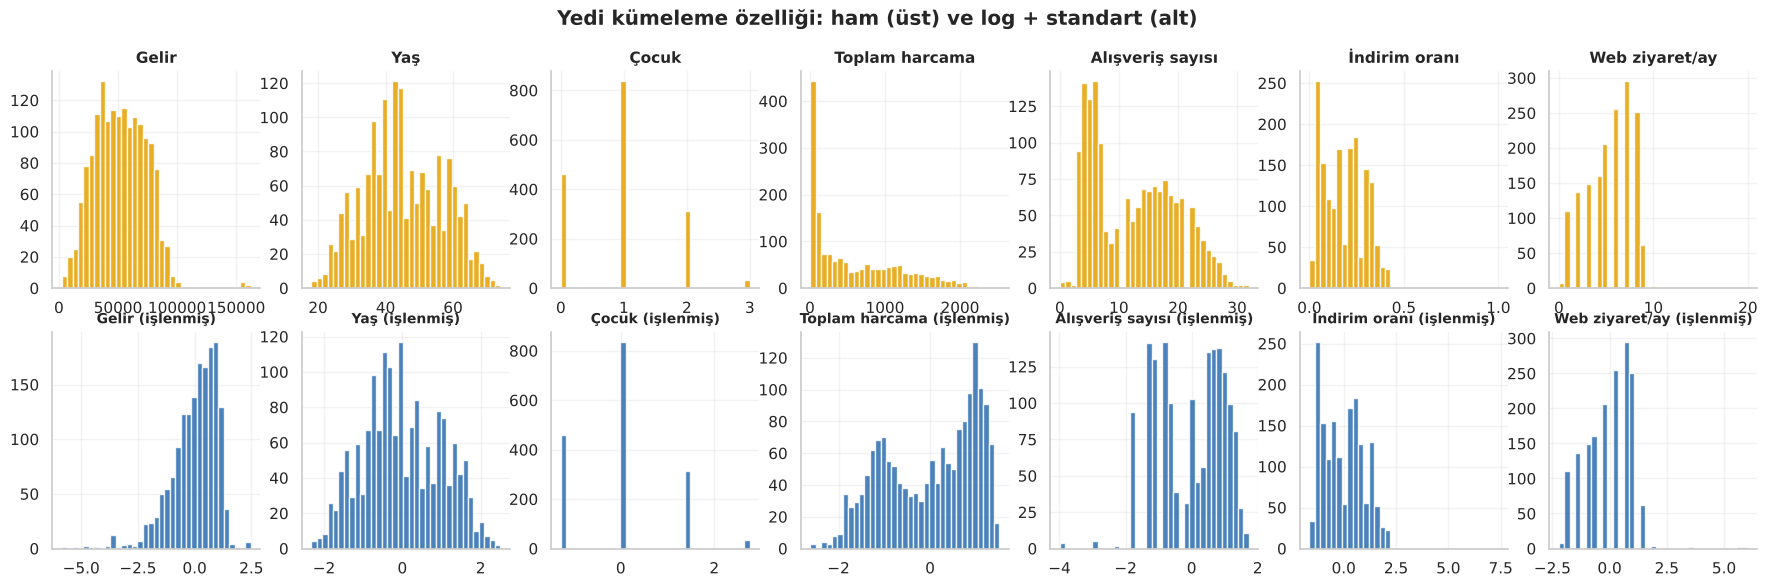

,Ham çarpıklık,İşlenmiş çarpıklık
Özellik,,
Gelir,0.41,-1.23
Yaş,0.10,0.10
Çocuk,0.38,0.38
Toplam harcama,0.87,-0.37
Alışveriş sayısı,0.32,-0.42
İndirim oranı,0.61,0.61
Web ziyaret/ay,0.23,0.23


📄 Rapor → outputs/reports/03_carpiklik.csv


In [7]:
fig, ax = plt.subplots(2, 7, figsize=(22, 6.2))
Ztr_df = pd.DataFrame(Ztr, columns=SUTUN)
carpik = []
for j, s in enumerate(KUME_OZELLIKLERI):
    x = Xtr[s].dropna()
    ax[0, j].hist(x, bins=35, color=RENK["altin"], alpha=.85); ax[0, j].set_title(s, fontsize=11)
    ax[1, j].hist(Ztr_df[s], bins=35, color=RENK["mavi"], alpha=.85); ax[1, j].set_title(f"{s} (işlenmiş)", fontsize=10)
    carpik.append({"Özellik": s, "Ham çarpıklık": stats.skew(x), "İşlenmiş çarpıklık": stats.skew(Ztr_df[s])})
fig.suptitle("Yedi kümeleme özelliği: ham (üst) ve log + standart (alt)", fontweight="bold")
kaydet(fig, "01_eda_dagilimlar"); plt.show()
carpik = pd.DataFrame(carpik).set_index("Özellik").round(2); display(carpik); rapor_kaydet(carpik, "03_carpiklik")

### 🔗 5.2 · Özellikler Arası İlişkiler ve Sepetin İçeriği

💾 Kaydedildi → outputs/figures/02_iliskiler_sepet.png


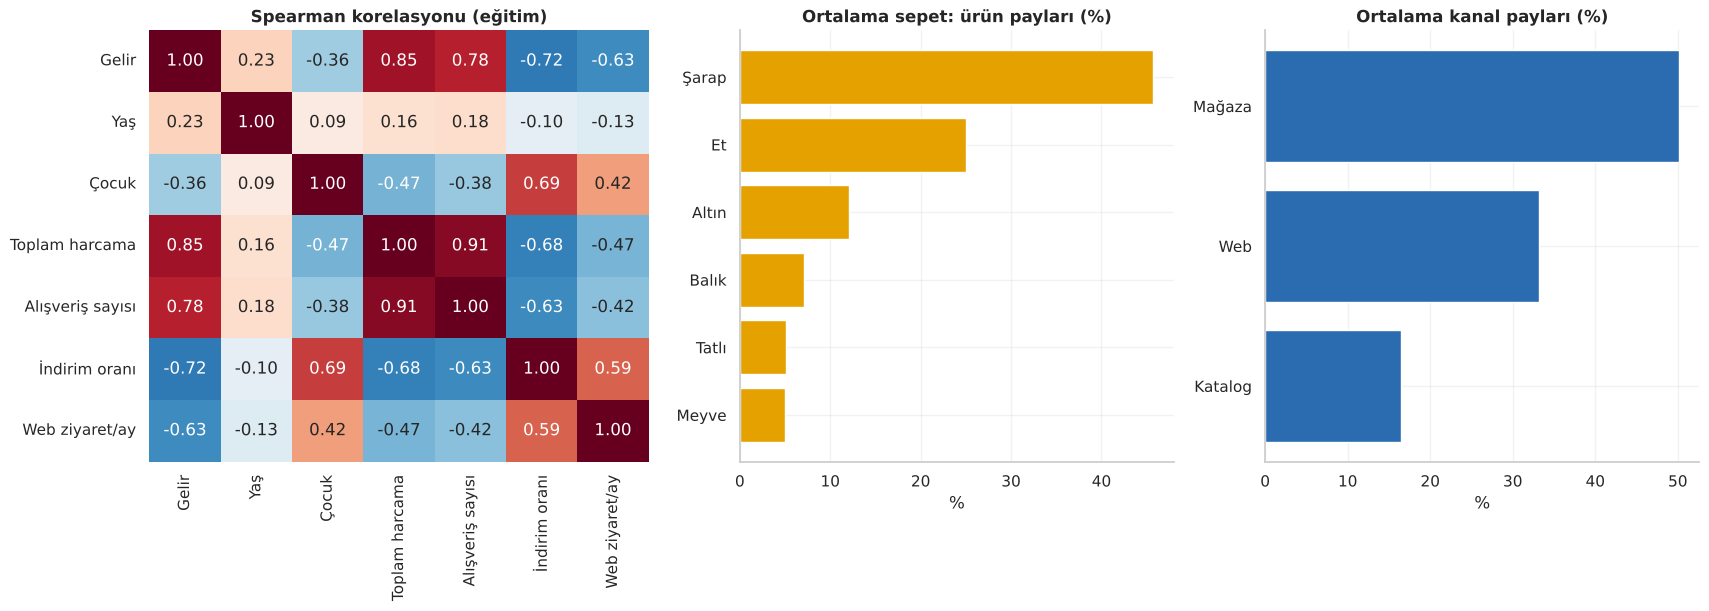

**En güçlü ilişkiler:** Toplam harcama ↔ Alışveriş sayısı: **+0.91**; Gelir ↔ Toplam harcama: **+0.85**; Gelir ↔ Alışveriş sayısı: **+0.78**; Gelir ↔ İndirim oranı: **-0.72**

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.6), gridspec_kw={"width_ratios": [1.15, 1, 1]})
kor = Ztr_df[KUME_OZELLIKLERI].corr(method="spearman")
sns.heatmap(kor, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title("Spearman korelasyonu (eğitim)")
urun = tr[[f"{v} payı" for v in URUN_TR.values()]].mean().sort_values()
ax[1].barh([u.replace(" payı", "") for u in urun.index], urun * 100, color=RENK["altin"]); ax[1].set(title="Ortalama sepet: ürün payları (%)", xlabel="%")
kanal = tr[["Web payı", "Katalog payı", "Mağaza payı"]].mean().sort_values()
ax[2].barh([k.replace(" payı", "") for k in kanal.index], kanal * 100, color=RENK["mavi"]); ax[2].set(title="Ortalama kanal payları (%)", xlabel="%")
kaydet(fig, "02_iliskiler_sepet"); plt.show()
guclu = kor.where(np.triu(np.ones_like(kor, bool), 1)).stack().sort_values(key=abs, ascending=False).head(4)
display(Markdown("**En güçlü ilişkiler:** " + "; ".join(f"{a} ↔ {b}: **{v:+.2f}**" for (a, b), v in guclu.items())))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Gelir, toplam harcama ve alışveriş sayısı** birbirine çok bağlı (hepsi "varlıklı ve aktif müşteri" sorusunun farklı yüzü); **çocuk sayısı** ve **indirim oranı** ise bunlarla **ters** yönde. Bu, segmentlerin büyük ölçüde bir **"varlık ekseni"** üzerinde sıralanacağını, aile yapısı ve fırsat kollama davranışının ise ikinci ayrımı yapacağını önceden söylüyor. Sepette **şarap ve et** baskın: ürün payları segment **profilinde** önemli olacak.

</td></tr></table>

### 🗺️ 5.3 · İlk Harita: Henüz Segment Yok

7 boyutlu müşteriyi görebilmek için iki boyutlu bir haritaya (PCA, yalnızca eğitimde öğrenilir) indiriyoruz. Bu harita **yalnızca görselleştirme** içindir; kümeleme 7 boyutta yapılır.

💾 Kaydedildi → outputs/figures/03_ilk_harita.png


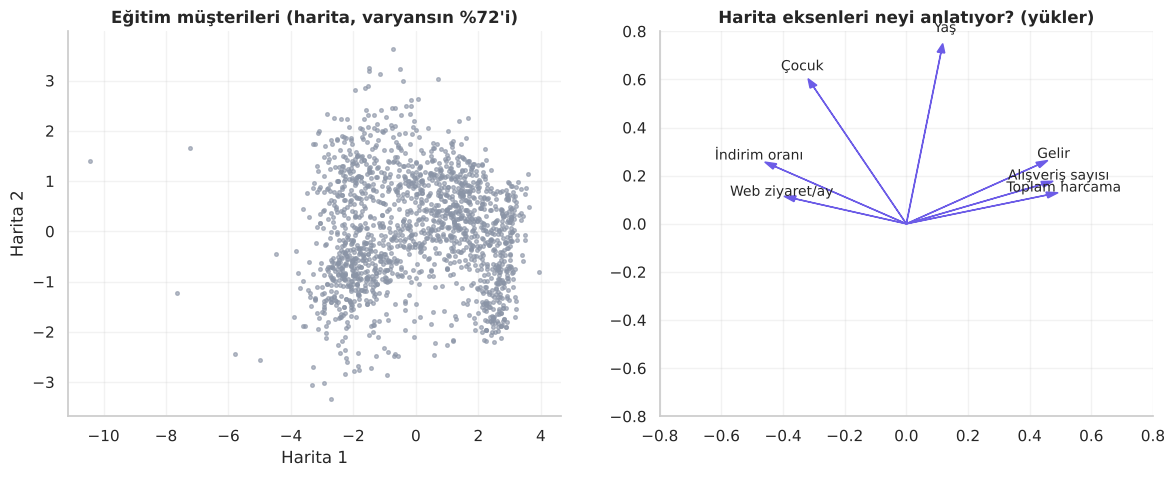

In [9]:
HARITA = PCA(3, random_state=RS).fit(Ztr)
Htr, Hte = HARITA.transform(Ztr), HARITA.transform(Zte)
oran = HARITA.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(Htr[:, 0], Htr[:, 1], s=7, color=RENK["gri"], alpha=.6); ax[0].set(title=f"Eğitim müşterileri (harita, varyansın %{oran[:2].sum() * 100:.0f}'i)", xlabel="Harita 1", ylabel="Harita 2")
yuk = pd.DataFrame(HARITA.components_[:2].T, index=SUTUN, columns=["Harita 1", "Harita 2"])
for s, (x, y) in yuk.iterrows():
    ax[1].arrow(0, 0, x, y, head_width=.025, color=RENK["mor"]); ax[1].annotate(s, (x * 1.12, y * 1.12), ha="center", fontsize=10)
ax[1].set(xlim=(-.8, .8), ylim=(-.8, .8), title="Harita eksenleri neyi anlatıyor? (yükler)")
kaydet(fig, "03_ilk_harita"); plt.show()

<a id="p6"></a>

<p align="center">
  <img src="assets/proje_06.svg" width="100%" alt="Bölüm 6: Ön işleme deneyi">
</p>


### 🧪 6.1 · Aynı K-Means, Beş Farklı Ön İşleme

Ön işleme, kümelemede **sonucu doğrudan belirler**: mesafeyi değiştirdiği için "kim kime benziyor?" sorusunun cevabı değişir. Aynı K-Means'i (k = 4) beş ön işlemeyle kurup iki şeye bakıyoruz:

- **Söz hakkı:** her özelliğin segmentleri ayırmadaki payı (η²). İdeal ön işleme, **tek bir özelliğe** her şeyi bırakmaz. **Söz hakkı dengesi** = η² dağılımının normalleştirilmiş entropisi (1 = herkes eşit, 0 = tek özellik).
- **Kararlılık:** 15 bootstrap örneğinde aynı segmentler çıkıyor mu (ARI)?

**Neden silüete bakmıyoruz?** Her ön işleme **farklı bir uzay** yaratır; farklı uzaylarda hesaplanan silüetler **birbiriyle kıyaslanamaz** (cetvelleri farklı).

,En baskın özellik,Baskın η²,Söz hakkı dengesi,Kararlılık (ARI),En küçük segment %
Ön işleme,,,,,
Ölçeksiz ham,Gelir,0.872,0.911,0.658,17.833
Standart (log yok),Toplam harcama,0.713,0.976,0.957,19.355
MinMax (log yok),Çocuk,0.782,0.959,0.952,18.503
Robust + log,Çocuk,0.696,0.975,0.968,18.624
Standart + log (seçilen),Çocuk,0.683,0.973,0.924,17.346


📄 Rapor → outputs/reports/04_on_isleme_deneyi.csv
💾 Kaydedildi → outputs/figures/04_on_isleme_soz_hakki.png


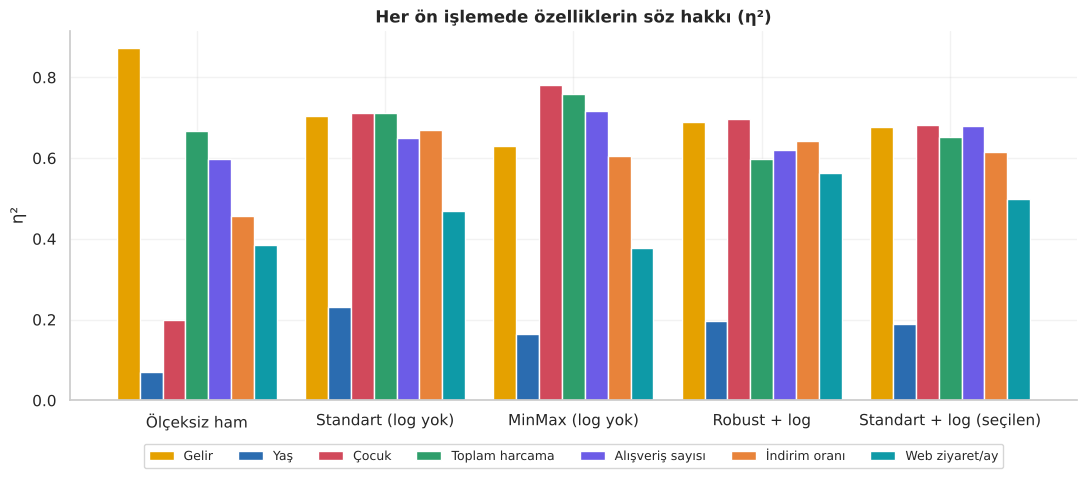

In [10]:
def eta_kare(x, et):
    genel = x.mean(); ara = sum((et == j).sum() * (x[et == j].mean() - genel) ** 2 for j in np.unique(et))
    return ara / ((x - genel) ** 2).sum()

def bootstrap_ari(model, Z, B=15, tohum=0):
    """Referans etiketleri tüm veriden, karşılaştırmayı bootstrap örneklerindeki ortak müşterilerden yapar."""
    ref = clone(model).fit_predict(Z); rng = np.random.default_rng(tohum); s = []
    for _ in range(B):
        i = np.unique(rng.choice(len(Z), len(Z)))
        s.append(adjusted_rand_score(ref[i], clone(model).fit_predict(Z[i])))
    return np.mean(s)

varyant = {"Ölçeksiz ham": on_isleme(None, log=False), "Standart (log yok)": on_isleme(StandardScaler(), log=False),
           "MinMax (log yok)": on_isleme(MinMaxScaler(), log=False), "Robust + log": on_isleme(RobustScaler()),
           "Standart + log (seçilen)": on_isleme(StandardScaler())}
Xdolu = SimpleImputer(strategy="median").fit(Xtr).transform(Xtr)       # η² ham birimde hesaplansın diye
sonuc, eta_tablo = [], {}
for ad, p in varyant.items():
    V = p.fit_transform(Xtr); km = KMeans(4, n_init=10, random_state=RS)
    et = km.fit_predict(V)
    eta = pd.Series([eta_kare(Xdolu[:, j], et) for j in range(7)], index=KUME_OZELLIKLERI); eta_tablo[ad] = eta
    pay = eta / eta.sum(); denge = float(-(pay * np.log(pay + 1e-12)).sum() / np.log(7))
    sonuc.append({"Ön işleme": ad, "En baskın özellik": eta.idxmax(), "Baskın η²": eta.max(), "Söz hakkı dengesi": denge,
                  "Kararlılık (ARI)": bootstrap_ari(km, V), "En küçük segment %": np.bincount(et).min() / len(et) * 100})
on_deney = pd.DataFrame(sonuc).set_index("Ön işleme").round(3); display(on_deney); rapor_kaydet(on_deney, "04_on_isleme_deneyi")

fig, ax = plt.subplots(figsize=(13, 4.8))
pd.DataFrame(eta_tablo).T.plot.bar(ax=ax, color=KUME_RENK[:7], width=.85)
ax.set(title="Her ön işlemede özelliklerin söz hakkı (η²)", ylabel="η²", xlabel=""); ax.tick_params(axis="x", rotation=0)
ax.legend(ncol=7, fontsize=9, loc="upper center", bbox_to_anchor=(.5, -.1))
kaydet(fig, "04_on_isleme_soz_hakki"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Ölçeksiz** kümelemede segmentleri neredeyse yalnızca **gelir** belirliyor (η² ≈ 1, denge en düşük): sayısı en büyük sütun her şeyi yutuyor. Ölçekleme bu tekeli kırıyor. **Log** ise çarpık harcamanın uç müşterilerini sıkıştırıp birkaç "çok zengin" müşterinin merkezleri çekmesini azaltıyor. İlginç bir ayrıntı: **MinMax** ölçekleme, yalnızca 0–3 değer alan **çocuk sayısını** 0–1 aralığına yayıp ona fazla söz hakkı veriyor. **Robust + log** ile **Standart + log** birbirine çok yakın (denge aynı düzeyde; kararlılıktaki fark 15 bootstrap'lık gürültülü bir ölçümde küçük). **Standart + log**'u seçtik: K-Means ve kalite ölçütleri ortalama/varyans dünyasında çalışıyor ve iki seçenek arasında anlamlı bir fark görünmüyor (Robust ile tekrar etmek 1. ödevin parçası). Bu karar test setine bakmadan, yalnızca eğitimde verildi.

</td></tr></table>

<a id="p7"></a>

<p align="center">
  <img src="assets/proje_07.svg" width="100%" alt="Bölüm 7: Kaç segment?">
</p>


### 🦵 7.1 · Beş Ölçüt, k = 2…10

Her k için K-Means (K-Means++, 10 deneme) kurup **dirsek (WCSS + diz noktası)**, **silüet**, **Davies-Bouldin**, **Calinski-Harabasz**, **bootstrap kararlılığı** (20 örnek) ve **en küçük segment payını** hesaplıyoruz. Sonra 2. bölümde yazdığımız **kural 1**'i uyguluyoruz.

In [11]:
def k_satiri(k):
    km = KMeans(k, n_init=10, random_state=RS); et = km.fit_predict(Ztr)
    return {"k": k, "WCSS": km.inertia_, "Silüet ↑": silhouette_score(Ztr, et), "Davies-Bouldin ↓": davies_bouldin_score(Ztr, et),
            "Calinski-Harabasz ↑": calinski_harabasz_score(Ztr, et), "Kararlılık ↑": bootstrap_ari(KMeans(k, n_init=10, random_state=RS), Ztr, B=20, tohum=k),
            "En küçük segment %": np.bincount(et).min() / len(et) * 100}
k_tablo = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(k_satiri)(k) for k in range(2, 11))).set_index("k")
wcss1 = KMeans(1, n_init=1).fit(Ztr).inertia_
try:
    from kneed import KneeLocator
    DIZ = KneeLocator([1] + list(k_tablo.index), [wcss1] + list(k_tablo["WCSS"]), curve="convex", direction="decreasing").elbow
except ImportError:
    DIZ = None
print("Dirsek (diz) noktası:", DIZ)

# ── Kural 1 ──
k_tablo["Uygun mu?"] = (k_tablo["Kararlılık ↑"] >= 0.85) & (k_tablo["En küçük segment %"] >= 8) & (k_tablo.index >= 3)
uygun = k_tablo[k_tablo["Uygun mu?"]].copy()
uygun["Ortalama sıra"] = pd.concat([uygun["Silüet ↑"].rank(ascending=False), uygun["Davies-Bouldin ↓"].rank(),
                                    uygun["Calinski-Harabasz ↑"].rank(ascending=False)], axis=1).mean(1)
K = int(uygun.sort_values(["Ortalama sıra"]).index[0]) if len(uygun) else 3
k_tablo["Ortalama sıra (uygunlar)"] = uygun["Ortalama sıra"]
display(k_tablo.round(3)); rapor_kaydet(k_tablo.round(4), "05_k_secimi")
display(Markdown(f"**Kural 1'in kararı: k = {K}.** Yalnızca geometrik ölçütlere bakılsaydı en iyi k = **{k_tablo['Silüet ↑'].idxmax()}** (silüet), "
                 f"**{k_tablo['Davies-Bouldin ↓'].idxmin()}** (DB), **{k_tablo['Calinski-Harabasz ↑'].idxmax()}** (CH) olurdu; dirsek noktası **{DIZ}**."))

Dirsek (diz) noktası: 3


,WCSS,Silüet ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,Kararlılık ↑,En küçük segment %,Uygun mu?,Ortalama sıra (uygunlar)
k,,,,,,,,
2,6615.921,0.371,1.084,1211.685,0.982,49.848,False,NaN
3,5534.204,0.267,1.309,884.105,0.952,29.884,True,1.000
4,4774.947,0.255,1.399,769.572,0.922,17.346,True,2.667
5,4306.715,0.246,1.309,684.062,0.976,14.912,True,2.667
6,4004.567,0.233,1.354,612.883,0.875,11.990,True,3.667
7,3731.341,0.223,1.430,567.766,0.773,9.069,False,NaN
8,3507.662,0.223,1.445,532.268,0.721,10.225,False,NaN
9,3319.845,0.225,1.402,503.337,0.703,6.878,False,NaN
10,3118.388,0.235,1.302,487.745,0.781,0.426,False,NaN


📄 Rapor → outputs/reports/05_k_secimi.csv


**Kural 1'in kararı: k = 3.** Yalnızca geometrik ölçütlere bakılsaydı en iyi k = **2** (silüet), **2** (DB), **2** (CH) olurdu; dirsek noktası **3**.

💾 Kaydedildi → outputs/figures/05_k_secimi.png


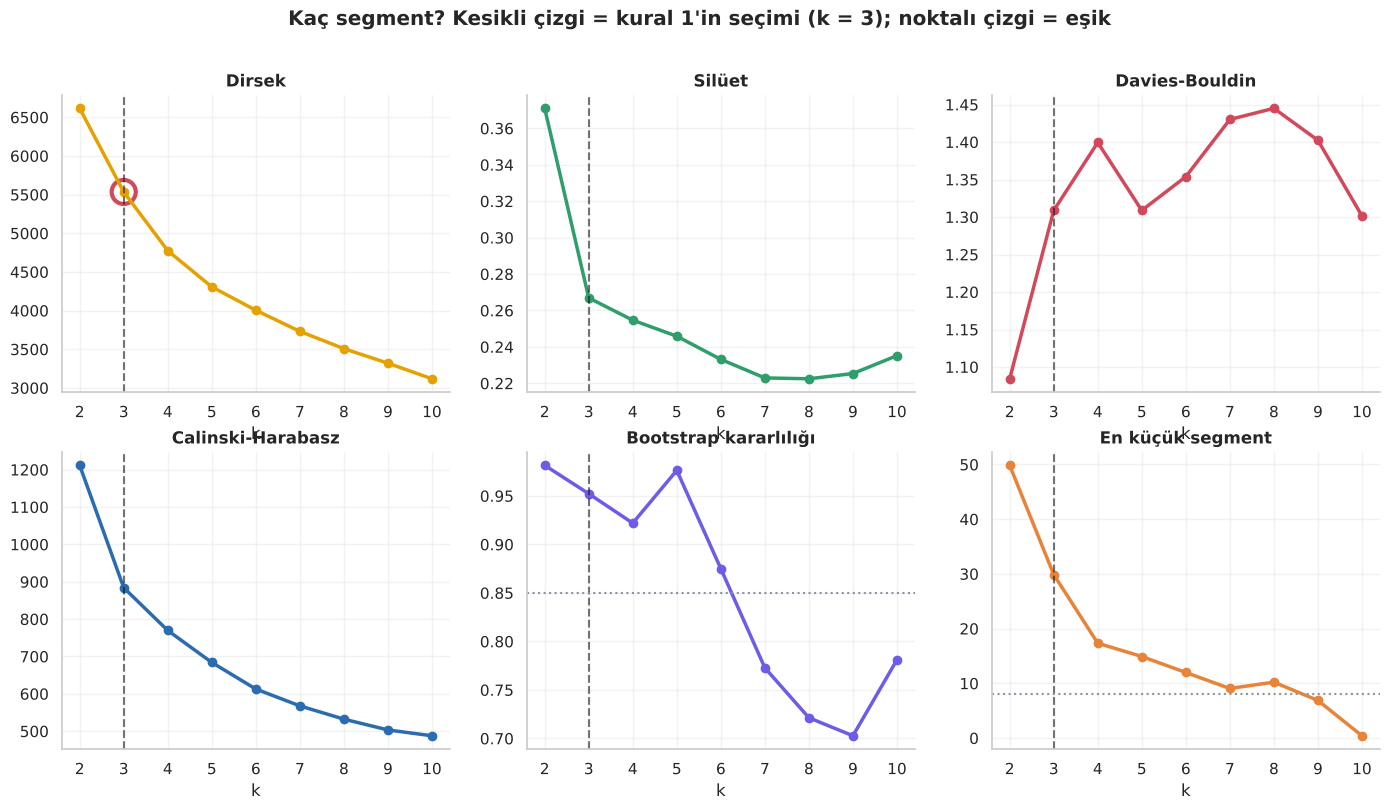

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
cizim = [("WCSS", RENK["altin"], "Dirsek"), ("Silüet ↑", RENK["yesil"], "Silüet"), ("Davies-Bouldin ↓", RENK["pembe"], "Davies-Bouldin"),
         ("Calinski-Harabasz ↑", RENK["mavi"], "Calinski-Harabasz"), ("Kararlılık ↑", RENK["mor"], "Bootstrap kararlılığı"), ("En küçük segment %", RENK["turuncu"], "En küçük segment")]
for a, (s, r, b) in zip(ax.ravel(), cizim):
    a.plot(k_tablo.index, k_tablo[s], "o-", color=r, lw=2.5); a.axvline(K, color="k", ls="--", alpha=.6); a.set(title=b, xlabel="k"); a.set_xticks(k_tablo.index)
    if s == "Kararlılık ↑": a.axhline(.85, color=RENK["gri"], ls=":")
    if s == "En küçük segment %": a.axhline(8, color=RENK["gri"], ls=":")
    if s == "WCSS" and DIZ: a.scatter([DIZ], [k_tablo.loc[DIZ, "WCSS"]], s=300, facecolor="none", edgecolor=RENK["pembe"], lw=3)
fig.suptitle(f"Kaç segment? Kesikli çizgi = kural 1'in seçimi (k = {K}); noktalı çizgi = eşik", fontweight="bold")
kaydet(fig, "05_k_secimi"); plt.show()

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Geometrik ölçütlerin en sevdiği k, çoğu müşteri verisinde olduğu gibi **en küçük k**'dır: en belirgin ayrım "varlıklı ve çok harcayan" ile "geri kalan" arasındadır. Kural 1 bu sonucu **gizlemiyor**, iş kısıtıyla (k ≥ 3) ve kararlılık/boyut şartlarıyla birlikte **şeffaf biçimde** dengeliyor. Kural sonuçlardan **önce** yazıldığı için "beğendiğimiz k'yı seçme" riski azaltıldı.

</td></tr></table>

### 🎞️ 7.2 · k Arttıkça Segment Haritası (Animasyon)

Aynı eğitim müşterileri, k = 2…8 için haritada. Başlıkta silüet ve kararlılık var: k büyüdükçe bölünme **inceliyor** ama kararlılık ve sıkılık **düşüyor**.

🎞️ Animasyon → outputs/figures/06_k_harita_animasyon.gif


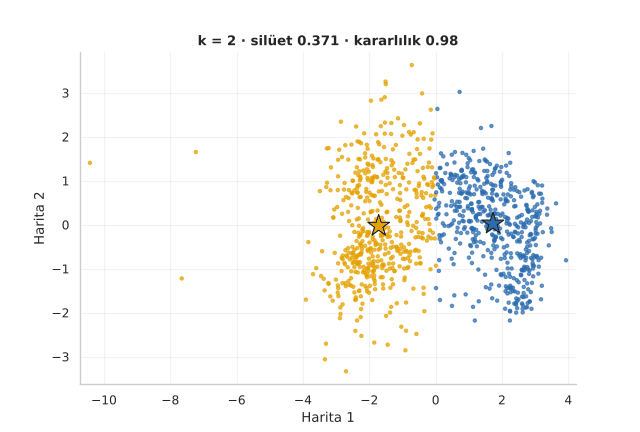

In [13]:
alt = np.random.default_rng(RS).choice(len(Ztr), 1000, replace=False)
k_et = {k: KMeans(k, n_init=10, random_state=RS).fit(Ztr) for k in range(2, 9)}
def kare(i, fig):
    k = min(i + 2, 8); m = k_et[k]; ax = fig.add_subplot(1, 1, 1)
    ax.scatter(Htr[alt, 0], Htr[alt, 1], s=9, c=[KUME_RENK[e] for e in m.labels_[alt]], alpha=.7)
    C = HARITA.transform(m.cluster_centers_)
    ax.scatter(C[:, 0], C[:, 1], s=420, marker="*", c=KUME_RENK[:k], edgecolor="k", zorder=5)
    ax.set(title=f"k = {k} · silüet {k_tablo.loc[k, 'Silüet ↑']:.3f} · kararlılık {k_tablo.loc[k, 'Kararlılık ↑']:.2f}" + ("  ← seçilen" if k == K else ""),
           xlabel="Harita 1", ylabel="Harita 2", xlim=(Htr[:, 0].min() - .3, Htr[:, 0].max() + .3), ylim=(Htr[:, 1].min() - .3, Htr[:, 1].max() + .3))
gif_kaydet(kare, 9, "06_k_harita_animasyon", figsize=(8, 5.4), fps=1)

<a id="p8"></a>

<p align="center">
  <img src="assets/proje_08.svg" width="100%" alt="Bölüm 8: Büyük yarış">
</p>


### 🏁 8.1 · Yarışçılar: 28 Algoritma + Rastgele Taban

<p align="center">
  <img src="assets/diyagram_aileler.svg" width="100%" alt="Algoritma aileleri">
</p>

Hepsi **aynı eğitim müşterileriyle**, **aynı 7 boyutlu ölçüm uzayında** (log + standart) yarışıyor. Segment sayısını parametre olarak alanlara **k = K** veriliyor; k'yı **kendisi bulan** algoritmalara (Mean Shift, DBSCAN, HDBSCAN, OPTICS, Affinity Propagation) veriye göre makul ayar veriliyor ve **ne bulurlarsa** o raporlanıyor. Yoğunluk algoritmalarının "gürültü" (−1) dediği müşteriler ölçütlerden çıkarılır ama **kapsama** oranına yansır.

In [14]:
# Yoğunluk tabanlı algoritmalar için veriye dayalı ayarlar (yalnızca eğitimden)
k_uzak = np.sort(NearestNeighbors(n_neighbors=8).fit(Ztr).kneighbors(Ztr)[0][:, -1])
EPS = float(np.quantile(k_uzak, 0.90))                                   # 8. komşu uzaklığının %90'lık dilimi
BANT = float(estimate_bandwidth(Ztr, quantile=0.2, random_state=RS))
TERCIH = float(np.min(-pairwise_distances(Ztr, squared=True)))           # Affinity Propagation: az küme için en küçük benzerlik

def yariscilar(K):
    """(aile, model) sözlüğü — her biri yalnızca tek iş parçacığı kullanır; paralellik algoritmalar arasında."""
    km = lambda **a: KMeans(K, random_state=RS, **a)
    gm = lambda c: GaussianMixture(K, covariance_type=c, n_init=5, random_state=RS)
    return {
        "K-Means (k-means++, 10 deneme)":      ("Merkez", km(n_init=10)),
        "K-Means (rastgele, 1 deneme)":        ("Merkez", km(init="random", n_init=1)),
        "K-Means (rastgele, 10 deneme)":       ("Merkez", km(init="random", n_init=10)),
        "K-Means (Elkan)":                     ("Merkez", km(n_init=10, algorithm="elkan")),
        "Mini-Batch K-Means":                  ("Merkez", MiniBatchKMeans(K, n_init=10, batch_size=256, random_state=RS)),
        "Bisecting K-Means (en büyük atalet)": ("Bölerek", BisectingKMeans(K, n_init=5, random_state=RS)),
        "Bisecting K-Means (en büyük küme)":   ("Bölerek", BisectingKMeans(K, n_init=5, bisecting_strategy="largest_cluster", random_state=RS)),
        "K-Medoids":                           ("Sağlam merkez", KMedoids(K, random_state=RS)),
        "K-Medyan (Manhattan)":                ("Sağlam merkez", KMedyan(K, random_state=RS)),
        "Bulanık C-Ortalamalar":               ("Sağlam merkez", BulanikCOrtalama(K, random_state=RS)),
        "PCA(3) + K-Means":                    ("Merkez", make_pipeline(PCA(3, random_state=RS), KMeans(K, n_init=10, random_state=RS))),
        "Hiyerarşik (Ward)":                   ("Hiyerarşik", AgglomerativeClustering(K, linkage="ward")),
        "Hiyerarşik (tam bağlantı)":           ("Hiyerarşik", AgglomerativeClustering(K, linkage="complete")),
        "Hiyerarşik (ortalama bağlantı)":      ("Hiyerarşik", AgglomerativeClustering(K, linkage="average")),
        "Hiyerarşik (tek bağlantı)":           ("Hiyerarşik", AgglomerativeClustering(K, linkage="single")),
        "BIRCH":                               ("Hiyerarşik", Birch(n_clusters=K, threshold=0.5)),
        "GMM (tam kovaryans)":                 ("Olasılık", gm("full")),
        "GMM (ortak kovaryans)":               ("Olasılık", gm("tied")),
        "GMM (köşegen kovaryans)":             ("Olasılık", gm("diag")),
        "GMM (küresel kovaryans)":             ("Olasılık", gm("spherical")),
        "Bayesçi GMM":                         ("Olasılık", BayesianGaussianMixture(n_components=K, n_init=5, random_state=RS)),
        "Spektral kümeleme (k-NN grafı)":      ("Graf", SpectralClustering(K, affinity="nearest_neighbors", n_neighbors=15, random_state=RS)),
        "Spektral kümeleme (RBF çekirdek)":    ("Graf", SpectralClustering(K, affinity="rbf", gamma=0.1, random_state=RS)),
        "Affinity Propagation":                ("Graf", AffinityPropagation(damping=0.9, preference=TERCIH, max_iter=500, random_state=RS)),
        "Mean Shift":                          ("Yoğunluk", MeanShift(bandwidth=BANT, bin_seeding=True)),
        "DBSCAN":                              ("Yoğunluk", DBSCAN(eps=EPS, min_samples=8)),
        "HDBSCAN":                             ("Yoğunluk", HDBSCAN(min_cluster_size=40)),
        "OPTICS":                              ("Yoğunluk", OPTICS(min_samples=15, xi=0.05)),
        "Rastgele taban":                      ("Taban", RastgeleTaban(K, random_state=RS)),
    }
YARISCI = yariscilar(K); AILE = {a: v[0] for a, v in YARISCI.items()}
print(f"Algoritma sayısı (taban hariç): {len(YARISCI) - 1} | DBSCAN eps = {EPS:.3f} | Mean Shift bant = {BANT:.3f}")
display(pd.Series(AILE).value_counts().rename("Algoritma sayısı").to_frame())

Algoritma sayısı (taban hariç): 28 | DBSCAN eps = 1.223 | Mean Shift bant = 2.299


,Algoritma sayısı
Merkez,6
Hiyerarşik,5
Olasılık,5
Yoğunluk,4
Sağlam merkez,3
Graf,3
Bölerek,2
Taban,1


### 🏎️ 8.2 · Yarışı Koşalım

Her algoritma için: **eğitimde kur** → iç ölçütler → **testi ata** (`predict` varsa en yakın merkez/olasılık; yoksa eğitim etiketlerinden 15 komşulu **k-NN uzatması**) → **test silüeti** → aynı algoritmayı testte **sıfırdan** kurup "eğitimden atanan" segmentlerle uyumu (**test ARI**) → **10 bootstrap** ile kararlılık. Paralel koşuyor; birkaç dakika sürebilir.

In [15]:
def etiketle(model, Z):
    m = clone(model); et = np.asarray(m.fit_predict(Z)); return m, et

def disari_ata(m, Ztr_, et_tr, Zyeni):
    """Eğitimde öğrenilen segmentleri yeni müşterilere taşır."""
    if hasattr(m, "predict"): return np.asarray(m.predict(Zyeni))
    ok = et_tr >= 0
    return KNeighborsClassifier(15).fit(Ztr_[ok], et_tr[ok]).predict(Zyeni)

def ic_olcutler(Z, et):
    ok = et >= 0; n_k = len(np.unique(et[ok]))
    if n_k < 2: return dict(sil=np.nan, db=np.nan, ch=np.nan)
    return dict(sil=silhouette_score(Z[ok], et[ok]), db=davies_bouldin_score(Z[ok], et[ok]), ch=calinski_harabasz_score(Z[ok], et[ok]))

def tek_algoritma(ad, model):
    t0 = time.perf_counter(); m, et = etiketle(model, Ztr); sure = time.perf_counter() - t0
    ok = et >= 0; boy = np.bincount(et[ok]) if ok.any() else np.array([0])
    io = ic_olcutler(Ztr, et)
    et_te = disari_ata(m, Ztr, et, Zte)
    te_sil = silhouette_score(Zte, et_te) if len(np.unique(et_te)) > 1 else np.nan
    _, et_te_yeni = etiketle(model, Zte)
    return {"Algoritma": ad, "Aile": AILE[ad], "Segment sayısı": len(boy), "Kapsama %": ok.mean() * 100,
            "En küçük segment %": boy.min() / len(et) * 100, "En büyük segment %": boy.max() / len(et) * 100,
            "Silüet": io["sil"], "Davies-Bouldin": io["db"], "Calinski-Harabasz": io["ch"],
            "Test silüeti": te_sil, "Test ARI (yeniden keşif)": adjusted_rand_score(et_te, et_te_yeni),
            "Yanıt ayrışması (V)": cramers_v(et[ok], tr["Son kampanya yanıtı"].to_numpy()[ok]), "Süre (sn)": sure}, et

def bootstrap_tek(ad, model, ref, b):
    i = np.unique(np.random.default_rng(1000 + b).choice(len(Ztr), len(Ztr)))
    _, et = etiketle(model, Ztr[i]); return ad, adjusted_rand_score(ref[i], et)

t0 = time.perf_counter()
cikti = Parallel(n_jobs=N_JOBS)(delayed(tek_algoritma)(a, m) for a, (_, m) in YARISCI.items())
yaris = pd.DataFrame([c[0] for c in cikti]).set_index("Algoritma"); ETIKET = {c[0]["Algoritma"]: c[1] for c in cikti}
bs = Parallel(n_jobs=N_JOBS)(delayed(bootstrap_tek)(a, m, ETIKET[a], b) for a, (_, m) in YARISCI.items() for b in range(10))
yaris["Kararlılık (ARI)"] = pd.DataFrame(bs, columns=["a", "ari"]).groupby("a")["ari"].mean()
print(f"⏱️ Yarış süresi: {time.perf_counter() - t0:.0f} sn")

# ── Kural 2: uygunluk ──
def neden(r):
    n = []
    if r["Kapsama %"] < 95: n.append(f"gürültü %{100 - r['Kapsama %']:.0f}")
    if r["En küçük segment %"] < 5: n.append(f"en küçük segment %{r['En küçük segment %']:.1f}")
    if not 2 <= r["Segment sayısı"] <= 10: n.append(f"{r['Segment sayısı']} segment")
    return ", ".join(n)
yaris["Uygun değilse neden?"] = yaris.apply(neden, axis=1); yaris["Uygun"] = yaris["Uygun değilse neden?"] == ""
u = yaris["Uygun"]
siralar = pd.concat([yaris.loc[u, "Silüet"].rank(ascending=False), yaris.loc[u, "Davies-Bouldin"].rank(),
                     yaris.loc[u, "Calinski-Harabasz"].rank(ascending=False), yaris.loc[u, "Kararlılık (ARI)"].rank(ascending=False),
                     yaris.loc[u, "Test silüeti"].rank(ascending=False)], axis=1)
yaris["Bileşik sıra"] = siralar.mean(1)
yaris = yaris.sort_values(["Uygun", "Bileşik sıra"], ascending=[False, True])
rapor_kaydet(yaris.round(4), "06_buyuk_yaris")
goster = ["Aile", "Segment sayısı", "Kapsama %", "En küçük segment %", "Silüet", "Davies-Bouldin", "Calinski-Harabasz",
          "Kararlılık (ARI)", "Test silüeti", "Test ARI (yeniden keşif)", "Yanıt ayrışması (V)", "Süre (sn)", "Bileşik sıra", "Uygun değilse neden?"]
display(yaris[goster].round(3))

⏱️ Yarış süresi: 12 sn
📄 Rapor → outputs/reports/06_buyuk_yaris.csv


,Aile,Segment sayısı,Kapsama %,En küçük segment %,Silüet,Davies-Bouldin,Calinski-Harabasz,Kararlılık (ARI),Test silüeti,Test ARI (yeniden keşif),Yanıt ayrışması (V),Süre (sn),Bileşik sıra,Uygun değilse neden?
Algoritma,,,,,,,,,,,,,,
K-Medoids,Sağlam merkez,3,100.000,22.763,0.274,1.278,864.585,0.870,0.275,0.780,0.159,0.188,6.0,
"K-Means (rastgele, 10 deneme)",Merkez,3,100.000,29.884,0.267,1.309,884.105,0.955,0.271,0.951,0.158,0.011,6.2,
"K-Means (k-means++, 10 deneme)",Merkez,3,100.000,29.884,0.267,1.309,884.105,0.948,0.271,0.937,0.158,0.028,6.4,
K-Means (Elkan),Merkez,3,100.000,29.884,0.267,1.309,884.105,0.948,0.271,0.937,0.158,0.074,6.4,
Bisecting K-Means (en büyük atalet),Bölerek,3,100.000,23.372,0.299,1.408,839.986,0.970,0.314,0.945,0.102,0.005,6.4,
K-Medyan (Manhattan),Sağlam merkez,3,100.000,24.772,0.269,1.305,861.590,0.943,0.273,0.925,0.185,0.052,6.8,
Hiyerarşik (Ward),Hiyerarşik,3,100.000,19.051,0.306,1.297,771.205,0.482,0.317,0.853,0.080,0.047,7.6,
Mini-Batch K-Means,Merkez,3,100.000,30.736,0.266,1.314,884.006,0.860,0.271,0.866,0.160,0.008,8.8,
BIRCH,Hiyerarşik,3,100.000,18.259,0.305,1.339,785.752,0.701,0.309,0.793,0.083,0.035,9.2,


### 📊 8.3 · Yarışın Görseli

💾 Kaydedildi → outputs/figures/07_buyuk_yaris.png


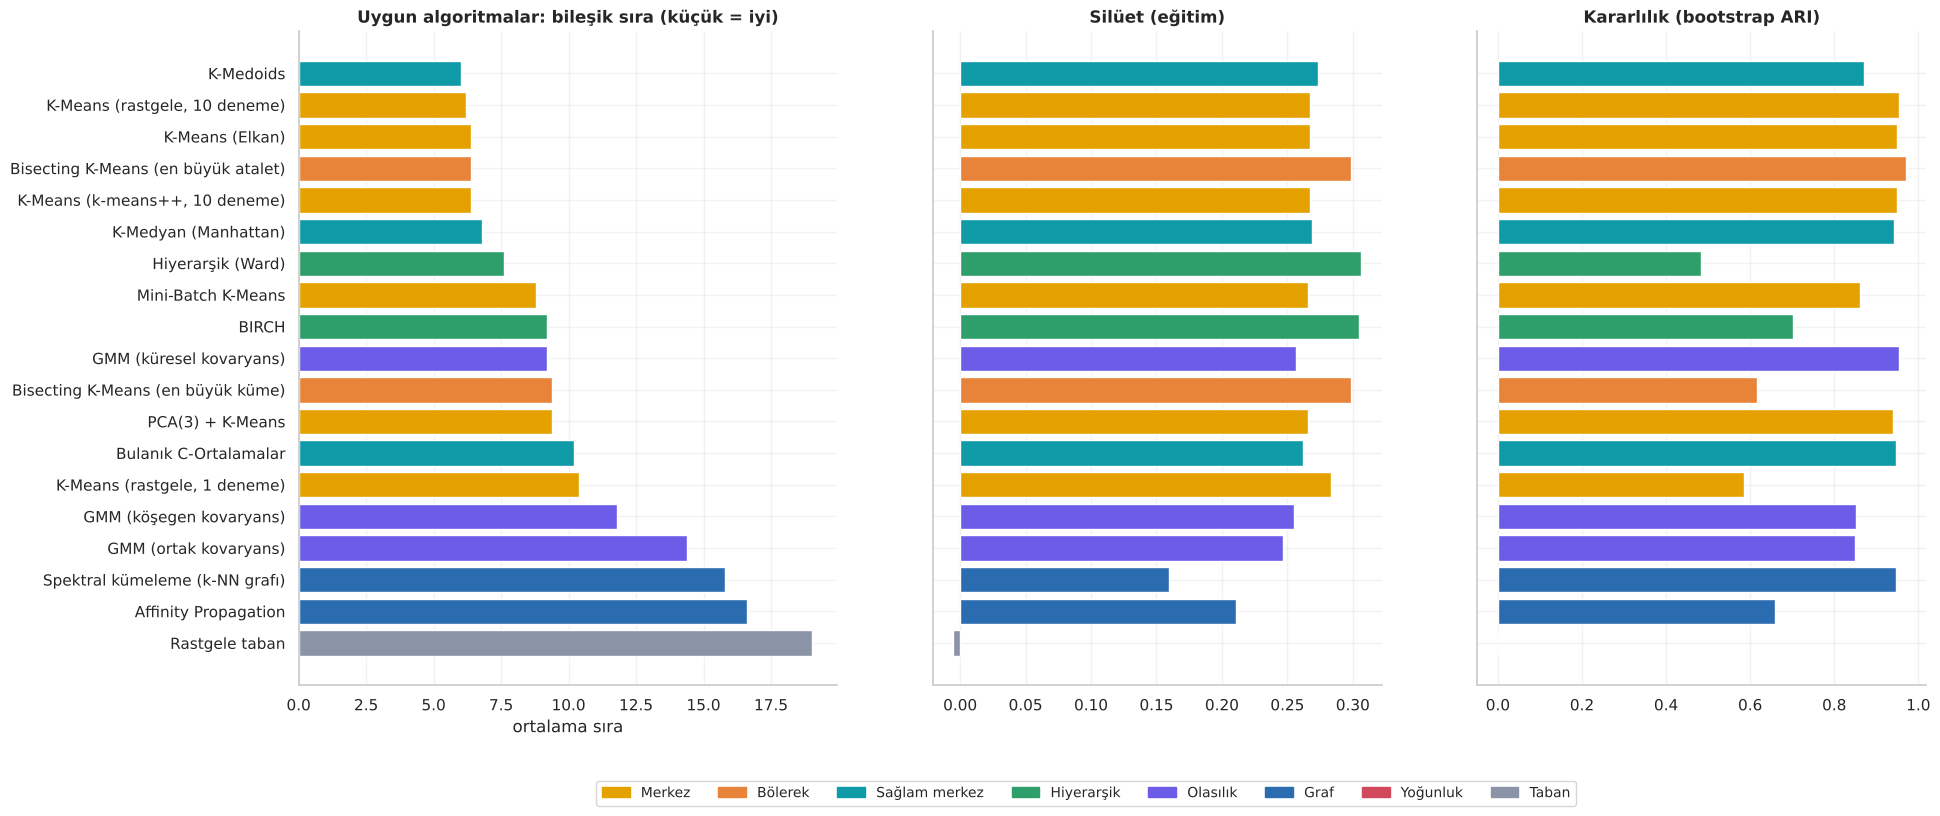

**Uygun olmayan 10 algoritma** (sıralanmadı):

,Segment sayısı,Kapsama %,En küçük segment %,Silüet,Uygun değilse neden?
Algoritma,,,,,
Hiyerarşik (tam bağlantı),3,100.000,0.426,0.262,en küçük segment %0.4
Hiyerarşik (ortalama bağlantı),3,100.000,0.183,0.564,en küçük segment %0.2
Hiyerarşik (tek bağlantı),3,100.000,0.061,0.606,en küçük segment %0.1
GMM (tam kovaryans),3,100.000,2.495,0.315,en küçük segment %2.5
Bayesçi GMM,3,100.000,2.374,0.327,en küçük segment %2.4
Spektral kümeleme (RBF çekirdek),3,100.000,0.061,0.662,en küçük segment %0.1
Mean Shift,14,100.000,0.061,0.340,"en küçük segment %0.1, 14 segment"
DBSCAN,4,96.105,1.156,0.109,en küçük segment %1.2
HDBSCAN,3,70.846,8.582,0.173,gürültü %29


In [16]:
aile_renk = {"Merkez": RENK["altin"], "Bölerek": RENK["turuncu"], "Sağlam merkez": RENK["cyan"], "Hiyerarşik": RENK["yesil"],
             "Olasılık": RENK["mor"], "Graf": RENK["mavi"], "Yoğunluk": RENK["pembe"], "Taban": RENK["gri"]}
uy = yaris[yaris["Uygun"]].sort_values("Bileşik sıra", ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(21, 8.5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
ax[0].barh(uy.index, uy["Bileşik sıra"], color=[aile_renk[a] for a in uy["Aile"]])
ax[0].set(title="Uygun algoritmalar: bileşik sıra (küçük = iyi)", xlabel="ortalama sıra")
for s, r, a in [("Silüet", "Silüet (eğitim)", ax[1]), ("Kararlılık (ARI)", "Kararlılık (bootstrap ARI)", ax[2])]:
    a.barh(uy.index, uy[s], color=[aile_renk[x] for x in uy["Aile"]]); a.set(title=r); a.set_yticklabels([])
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=a) for a, c in aile_renk.items()], loc="lower center", ncol=8, fontsize=10, bbox_to_anchor=(.5, -.04))
kaydet(fig, "07_buyuk_yaris"); plt.show()

uygunsuz = yaris[~yaris["Uygun"]][["Segment sayısı", "Kapsama %", "En küçük segment %", "Silüet", "Uygun değilse neden?"]].round(3)
display(Markdown(f"**Uygun olmayan {len(uygunsuz)} algoritma** (sıralanmadı):")); display(uygunsuz)

In [17]:
lider, ikinci = yaris.index[0], yaris.index[1]
en_yuksek_sil = yaris["Silüet"].idxmax()
display(Markdown(
    f"**Okuma:** uygun algoritmalar arasında bileşik sırada lider **{lider}** (silüet {yaris.loc[lider, 'Silüet']:.3f}, kararlılık {yaris.loc[lider, 'Kararlılık (ARI)']:.3f}), "
    f"ikinci **{ikinci}** (silüet {yaris.loc[ikinci, 'Silüet']:.3f}, kararlılık {yaris.loc[ikinci, 'Kararlılık (ARI)']:.3f}). "
    f"Tüm tabloda **en yüksek silüet** ise **{en_yuksek_sil}** algoritmasında ({yaris.loc[en_yuksek_sil, 'Silüet']:.3f}) — ama bu algoritma "
    f"{'uygun' if yaris.loc[en_yuksek_sil, 'Uygun'] else 'UYGUN DEĞİL: ' + yaris.loc[en_yuksek_sil, 'Uygun değilse neden?']}. "
    f"Rastgele taban: silüet {yaris.loc['Rastgele taban', 'Silüet']:.3f}, kararlılık {yaris.loc['Rastgele taban', 'Kararlılık (ARI)']:.3f}."))

**Okuma:** uygun algoritmalar arasında bileşik sırada lider **K-Medoids** (silüet 0.274, kararlılık 0.870), ikinci **K-Means (rastgele, 10 deneme)** (silüet 0.267, kararlılık 0.955). Tüm tabloda **en yüksek silüet** ise **Spektral kümeleme (RBF çekirdek)** algoritmasında (0.662) — ama bu algoritma UYGUN DEĞİL: en küçük segment %0.1. Rastgele taban: silüet -0.005, kararlılık -0.000.

### 🪤 8.4 · Silüet Tuzağı: En Yüksek Skor, En Kötü Segmentasyon

💾 Kaydedildi → outputs/figures/08_siluet_tuzagi.png


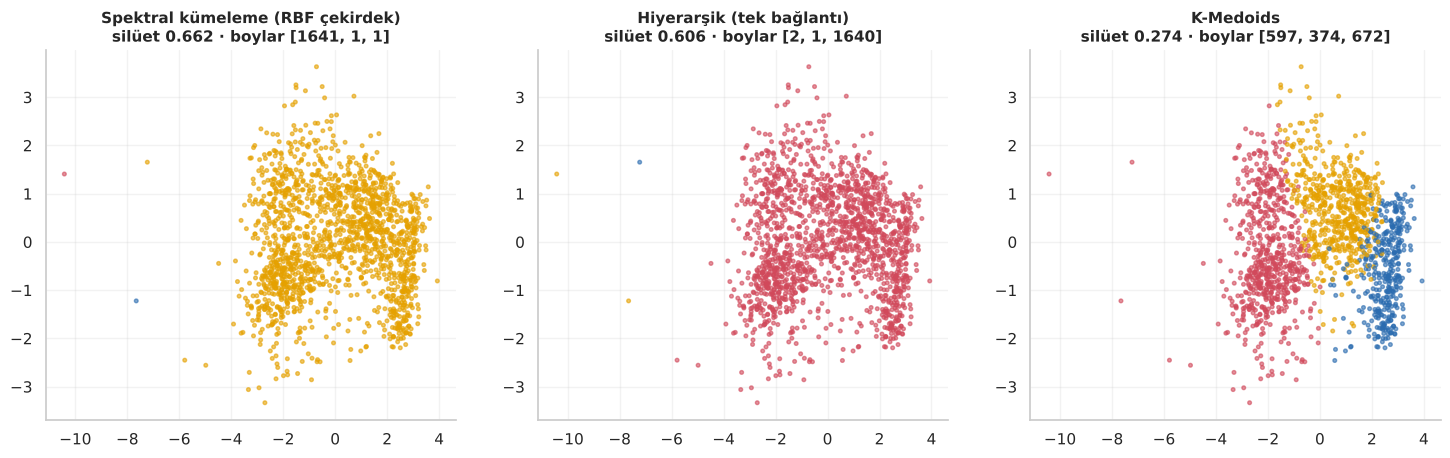

In [18]:
tuzak = ["Spektral kümeleme (RBF çekirdek)", "Hiyerarşik (tek bağlantı)", lider]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a, ad in zip(ax, tuzak):
    et = ETIKET[ad]; boy = pd.Series(et).value_counts().sort_index()
    a.scatter(Htr[:, 0], Htr[:, 1], s=7, c=[KUME_RENK[e % 10] if e >= 0 else "#BBBBBB" for e in et], alpha=.6)
    a.set_title(f"{ad}\nsilüet {yaris.loc[ad, 'Silüet']:.3f} · boylar {boy.tolist()}", fontsize=11)
kaydet(fig, "08_siluet_tuzagi"); plt.show()

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

**RBF çekirdekli spektral kümeleme** ile **tek ve ortalama bağlantılı** hiyerarşik kümeleme tablonun en yüksek silüetlerini alıyor; çünkü müşterilerin neredeyse tamamını **tek bir dev segmente** koyup bir-iki uç müşteriyi ayrı "segment" yapıyorlar. Tam kovaryanslı GMM ve Bayesçi GMM de benzer biçimde %2–3'lük küçük bir "uç müşteri" segmenti üretip eleniyor. Silüet bu durumda "çok ayrık gruplar" görür, ama pazarlama açısından bu **hiçbir şey söylemez**. Kural 2'deki **en küçük segment** şartı bu tuzağı yakalar. Ders: **tek bir ölçüte asla güvenmeyin**; segment boylarına mutlaka bakın. Yoğunluk algoritmalarının çoğu da uygun değil: müşteri verisi **yoğunluk boşlukları olmayan sürekli bir bulut**; bu algoritmalar ya her şeyi tek grup ya da çoğu müşteriyi gürültü sayıyor.

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/proje_09.svg" width="100%" alt="Bölüm 9: Kararlılık">
</p>


### 📊 9.1 · İlk 6 Uygun Algoritma: 40 Bootstrap ve 10 Tohum

Yarıştaki kararlılık 10 bootstrap ile ölçüldü; ilk altı uygun algoritmayı **40 bootstrap** ile yeniden ölçüp dağılımına bakıyoruz. Ayrıca **tohum duyarlılığı**: aynı veriyle yalnızca `random_state`'i değiştirince segmentler ne kadar değişiyor (10 tohum, ikili ARI ortalaması)?

,ortalama,alt_5,std,Tohum ARI (deterministikse boş)
Algoritma,,,,
K-Medoids,0.884,0.766,0.118,0.948
"K-Means (rastgele, 10 deneme)",0.915,0.829,0.093,1.000
"K-Means (k-means++, 10 deneme)",0.919,0.837,0.092,1.000
K-Means (Elkan),0.919,0.837,0.092,1.000
Bisecting K-Means (en büyük atalet),0.968,0.932,0.020,1.000
K-Medyan (Manhattan),0.966,0.936,0.022,1.000


📄 Rapor → outputs/reports/07_kararlilik.csv


**Okuma:** 40 bootstrap'ta ortalama ARI'si 0,85'in üstünde olanlar: **K-Medoids** (0.884, alt %5: 0.766), **K-Means (rastgele, 10 deneme)** (0.915, alt %5: 0.829), **K-Means (k-means++, 10 deneme)** (0.919, alt %5: 0.837), **K-Means (Elkan)** (0.919, alt %5: 0.837), **Bisecting K-Means (en büyük atalet)** (0.968, alt %5: 0.932), **K-Medyan (Manhattan)** (0.966, alt %5: 0.936). En oynak olan: **K-Medoids**.

💾 Kaydedildi → outputs/figures/09_kararlilik_kutu.png


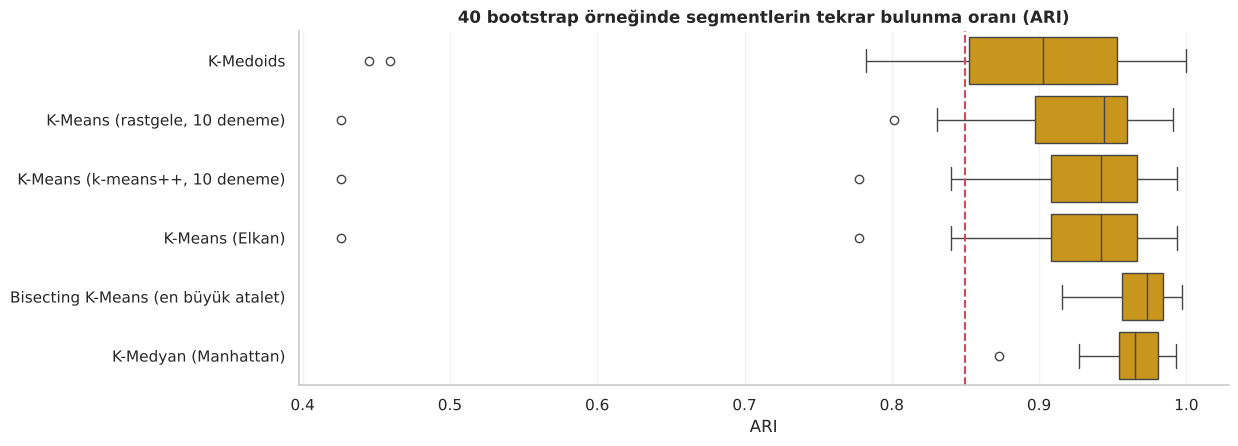

In [19]:
ilk6 = [a for a in yaris.index if yaris.loc[a, "Uygun"] and a != "Rastgele taban"][:6]
bs40 = Parallel(n_jobs=N_JOBS)(delayed(bootstrap_tek)(a, YARISCI[a][1], ETIKET[a], 100 + b) for a in ilk6 for b in range(40))
bs40 = pd.DataFrame(bs40, columns=["Algoritma", "ARI"])

def tohum_ari(ad):
    m = YARISCI[ad][1]
    if "random_state" not in m.get_params() and not any(k.endswith("random_state") for k in m.get_params()):
        return ad, np.nan                                              # deterministik algoritma (ör. Ward)
    ets = []
    for t in range(10):
        mm = clone(m); mm.set_params(**{k: t for k in mm.get_params() if k.endswith("random_state")}); ets.append(mm.fit_predict(Ztr))
    return ad, np.mean([adjusted_rand_score(ets[i], ets[j]) for i in range(10) for j in range(i + 1, 10)])
tohum = dict(Parallel(n_jobs=N_JOBS)(delayed(tohum_ari)(a) for a in ilk6))
karar_tab = bs40.groupby("Algoritma")["ARI"].agg(ortalama="mean", alt_5="quantile", std="std").reindex(ilk6)
karar_tab["alt_5"] = bs40.groupby("Algoritma")["ARI"].quantile(.05).reindex(ilk6)
karar_tab["Tohum ARI (deterministikse boş)"] = pd.Series(tohum)
display(karar_tab.round(3)); rapor_kaydet(karar_tab.round(4), "07_kararlilik")
display(Markdown("**Okuma:** 40 bootstrap'ta ortalama ARI'si 0,85'in üstünde olanlar: " + ", ".join(f"**{a}** ({v:.3f}, alt %5: {karar_tab.loc[a, 'alt_5']:.3f})" for a, v in karar_tab["ortalama"].items() if v >= .85)
                 + ". En oynak olan: **" + karar_tab["std"].idxmax() + "**."))

fig, ax = plt.subplots(figsize=(12, 4.6))
sns.boxplot(data=bs40, y="Algoritma", x="ARI", order=ilk6, ax=ax, color=RENK["altin"]); ax.axvline(.85, color=RENK["pembe"], ls="--")
ax.set(title="40 bootstrap örneğinde segmentlerin tekrar bulunma oranı (ARI)", ylabel="")
kaydet(fig, "09_kararlilik_kutu"); plt.show()

### 🎞️ 9.2 · Bootstrap'ta Merkezler Ne Kadar Oynuyor? (Animasyon)

Merkez tabanlı ailenin temsilcisi **K-Means**'in 25 bootstrap örneğindeki merkezleri haritaya tek tek ekleniyor. Merkez bulutları **küçük ve ayrık** kaldıkça segmentler kararlıdır.

🎞️ Animasyon → outputs/figures/10_bootstrap_merkezler.gif


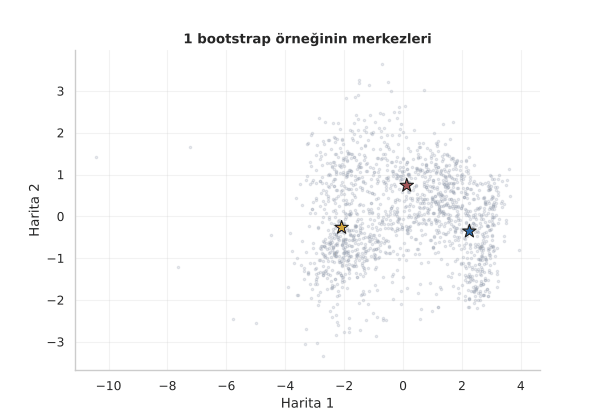

In [20]:
bs_merkez = []
for b in range(25):
    i = np.random.default_rng(500 + b).choice(len(Ztr), len(Ztr))
    m = KMeans(K, n_init=10, random_state=RS).fit(Ztr[i])
    ref = KMeans(K, n_init=10, random_state=RS).fit(Ztr).cluster_centers_
    sira = [int(np.argmin(((m.cluster_centers_ - r) ** 2).sum(1))) for r in ref]      # aynı segmenti aynı renge eşle
    bs_merkez.append(HARITA.transform(m.cluster_centers_[sira]))
def kare(i, fig):
    ax = fig.add_subplot(1, 1, 1); n = min(i + 1, 25)
    ax.scatter(Htr[:, 0], Htr[:, 1], s=5, color=RENK["gri"], alpha=.2)
    for b in range(n):
        ax.scatter(bs_merkez[b][:, 0], bs_merkez[b][:, 1], s=160, marker="*", c=KUME_RENK[:K], edgecolor="k", alpha=.35 if b < n - 1 else 1)
    ax.set(title=f"{n} bootstrap örneğinin merkezleri", xlabel="Harita 1", ylabel="Harita 2")
gif_kaydet(kare, 28, "10_bootstrap_merkezler", figsize=(7.5, 5.2), fps=4)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

K-Means merkezleri bootstrap örneklerinde **küçük bulutlar** hâlinde kalıyor: segmentler tesadüf değil, verinin **sağlam bir yapısı**. En kararlılar **K-Medyan** ve **Bisecting K-Means** (alt %5'lik dilim bile 0,93'ün üstünde); **K-Medoids** ortalamada eşiği geçiyor ama en oynak olanı. Yarış tablosundaki iki uyarıya da dikkat: **Hiyerarşik Ward** tohumsuz, yani deterministik; yine de bootstrap kararlılığı yalnızca ≈ 0,48. **Deterministik olmak kararlı olmak demek değildir**: veri biraz değişince Ward'ın ağacı farklı yerden kesiliyor. **Tek denemeli rastgele K-Means** de (≈ 0,59) kavram notebook'undaki başlangıç tuzağını gerçek veride gösteriyor.

</td></tr></table>

<a id="p10"></a>

<p align="center">
  <img src="assets/proje_10.svg" width="100%" alt="Bölüm 10: Ayar">
</p>


### 🛠️ 10.1 · Düğmeleri Çevirmek (Ölçüm Uzayı Sabit)

Yarışın **üst sıralarındaki beş aileyi** seçip düğmelerini tarıyoruz. **Önemli kural:** ayar sırasında **ölçüm uzayı değişmez** (aynı 7 özellik, aynı log + standart); yalnızca algoritmanın kendi düğmeleri değişir. Aksi hâlde farklı cetvellerle ölçülmüş skorları kıyaslamış oluruz. k = K sabittir (kural 1).

| Aday | Taranan düğmeler |
|:--|:--|
| K-Means | başlangıç (`k-means++`, `random`), deneme sayısı (1, 5, 10, 30), algoritma (`lloyd`, `elkan`) |
| K-Medoids | deneme sayısı (1, 3, 5, 10), en fazla tur (10, 100) |
| Bisecting K-Means | bölme stratejisi (2), başlangıç (`k-means++`, `random`), deneme sayısı (1, 5, 10) |
| GMM | kovaryans tipi (4), düzenleme (`reg_covar`), başlatma (`kmeans`, `k-means++`, `random_from_data`) |
| BIRCH | eşik (0,3–1,2), dal sayısı (25, 50, 100) |

Her ayar için **silüet, DB, CH ve 10 bootstrap kararlılığı** hesaplanır; tüm adaylar birlikte **bileşik sıraya** girer.

In [21]:
import itertools
aday = []
for init, n_init, alg in itertools.product(["k-means++", "random"], [1, 5, 10, 30], ["lloyd", "elkan"]):
    aday.append(("K-Means", f"init={init}, n_init={n_init}, {alg}", KMeans(K, init=init, n_init=n_init, algorithm=alg, random_state=RS)))
for cov, reg, ini in itertools.product(["full", "tied", "diag", "spherical"], [1e-6, 1e-3, 1e-1], ["kmeans", "k-means++", "random_from_data"]):
    aday.append(("GMM", f"{cov}, reg={reg:g}, init={ini}", GaussianMixture(K, covariance_type=cov, reg_covar=reg, init_params=ini, n_init=5, random_state=RS)))
for n_init, mi in itertools.product([1, 3, 5, 10], [10, 100]):
    aday.append(("K-Medoids", f"n_init={n_init}, max_iter={mi}", KMedoids(K, n_init=n_init, max_iter=mi, random_state=RS)))
for strat, init, n_init in itertools.product(["biggest_inertia", "largest_cluster"], ["k-means++", "random"], [1, 5, 10]):
    aday.append(("Bisecting", f"{strat}, init={init}, n_init={n_init}", BisectingKMeans(K, bisecting_strategy=strat, init=init, n_init=n_init, random_state=RS)))
for esik, dal in itertools.product([0.3, 0.5, 0.8, 1.2], [25, 50, 100]):
    aday.append(("BIRCH", f"eşik={esik}, dal={dal}", Birch(n_clusters=K, threshold=esik, branching_factor=dal)))

def ayar_degerlendir(aile, ayar, model):
    _, et = etiketle(model, Ztr); io = ic_olcutler(Ztr, et)
    st = np.mean([adjusted_rand_score(et[i], etiketle(model, Ztr[i])[1])
                      for i in [np.unique(np.random.default_rng(2000 + b).choice(len(Ztr), len(Ztr))) for b in range(10)]])
    return {"Aile": aile, "Ayar": ayar, "Silüet": io["sil"], "Davies-Bouldin": io["db"], "Calinski-Harabasz": io["ch"],
            "Kararlılık (ARI)": st, "En küçük segment %": np.bincount(et).min() / len(et) * 100}

t0 = time.perf_counter()
ayar = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(ayar_degerlendir)(*a) for a in aday))
print(f"{len(ayar)} ayar denendi · {time.perf_counter() - t0:.0f} sn")
ay = ayar[(ayar["En küçük segment %"] >= 5) & (ayar["Kararlılık (ARI)"].fillna(0) >= 0.85)].copy()
ay["Bileşik sıra"] = pd.concat([ay["Silüet"].rank(ascending=False), ay["Davies-Bouldin"].rank(), ay["Calinski-Harabasz"].rank(ascending=False),
                                ay["Kararlılık (ARI)"].rank(ascending=False)], axis=1).mean(1)
en_iyi_ayar = ay.sort_values("Bileşik sıra").groupby("Aile").head(1).sort_values("Bileşik sıra")
rapor_kaydet(ayar.round(4), "08_ayar_tum", index=False)
display(Markdown(f"**Uygunluk şartını geçen {len(ay)} / {len(ayar)} ayar.** Her ailenin en iyi ayarı:")); display(en_iyi_ayar.round(4))
# Yarıştaki (varsayılan) ayar ile en iyi uygun ayarın karşılaştırması
varsayilan = {"K-Means": "init=k-means++, n_init=10, lloyd", "K-Medoids": "n_init=5, max_iter=100", "Bisecting": "biggest_inertia, init=random, n_init=5",
              "GMM": "full, reg=1e-06, init=kmeans", "BIRCH": "eşik=0.5, dal=50"}
satir = []
for a, v in varsayilan.items():
    r0 = ayar[(ayar["Aile"] == a) & (ayar["Ayar"] == v)].iloc[0]
    uygun0 = bool((r0["En küçük segment %"] >= 5) and (r0["Kararlılık (ARI)"] >= 0.85))
    r1 = en_iyi_ayar.set_index("Aile").loc[a] if a in set(en_iyi_ayar["Aile"]) else None
    satir.append({"Aile": a, "Yarıştaki ayar": v, "Silüet (yarış ayarı)": r0["Silüet"], "Kararlılık (yarış ayarı)": r0["Kararlılık (ARI)"], "Uygun mu?": uygun0,
                  "En iyi uygun ayar": None if r1 is None else r1["Ayar"], "Silüet (en iyi)": np.nan if r1 is None else r1["Silüet"],
                  "Kararlılık (en iyi)": np.nan if r1 is None else r1["Kararlılık (ARI)"]})
fark = pd.DataFrame(satir).set_index("Aile"); display(fark.round(4)); rapor_kaydet(fark.round(4), "09_ayar_kazanci", index=False)

84 ayar denendi · 8 sn
📄 Rapor → outputs/reports/08_ayar_tum.csv


**Uygunluk şartını geçen 36 / 84 ayar.** Her ailenin en iyi ayarı:

,Aile,Ayar,Silüet,Davies-Bouldin,Calinski-Harabasz,Kararlılık (ARI),En küçük segment %,Bileşik sıra
59,K-Medoids,"n_init=10, max_iter=100",0.2736,1.2781,864.5853,0.9218,22.7632,12.25
7,K-Means,"init=k-means++, n_init=30, elkan",0.2669,1.3087,884.1049,0.9319,29.8844,12.50
63,Bisecting,"biggest_inertia, init=random, n_init=1",0.2999,1.4030,839.2127,0.9635,23.3719,14.25
50,GMM,"spherical, reg=0.1, init=k-means++",0.2647,1.2859,845.8773,0.9002,23.5545,18.00


,Yarıştaki ayar,Silüet (yarış ayarı),Kararlılık (yarış ayarı),Uygun mu?,En iyi uygun ayar,Silüet (en iyi),Kararlılık (en iyi)
Aile,,,,,,,
K-Means,"init=k-means++, n_init=10, lloyd",0.2669,0.9287,True,"init=k-means++, n_init=30, elkan",0.2669,0.9319
K-Medoids,"n_init=5, max_iter=100",0.2736,0.8833,True,"n_init=10, max_iter=100",0.2736,0.9218
Bisecting,"biggest_inertia, init=random, n_init=5",0.2988,0.9618,True,"biggest_inertia, init=random, n_init=1",0.2999,0.9635
GMM,"full, reg=1e-06, init=kmeans",0.3153,0.5359,False,"spherical, reg=0.1, init=k-means++",0.2647,0.9002
BIRCH,"eşik=0.5, dal=50",0.3046,0.6539,False,NaN,NaN,NaN


📄 Rapor → outputs/reports/09_ayar_kazanci.csv


### 🏆 10.2 · Final Seçimi (Kural 3)

Ayarlı adayları **yeni (taze) 30 bootstrap örneğiyle** bir kez daha ölçüp kural 3'ü uyguluyoruz: bileşik sıra en iyi olan; ilk ikisi arasında silüet farkı ≤ 0,01 **ve** kararlılık farkı ≤ 0,02 ise **merkez tabanlı** olan.

In [22]:
MERKEZ_TABANLI = (KMeans, MiniBatchKMeans, BisectingKMeans, KMedoids, KMedyan, BulanikCOrtalama, GaussianMixture, Birch)
modeller_final = {}
for _, r in en_iyi_ayar.iterrows():
    modeller_final[f"{r['Aile']} ({r['Ayar']})"] = [m for a, s, m in aday if a == r["Aile"] and s == r["Ayar"]][0]
def taze(ad, m):
    _, ref = etiketle(m, Ztr)
    return ad, np.mean([adjusted_rand_score(ref[i], etiketle(m, Ztr[i])[1]) for i in [np.unique(np.random.default_rng(9000 + b).choice(len(Ztr), len(Ztr))) for b in range(30)]])
taze_st = dict(Parallel(n_jobs=N_JOBS)(delayed(taze)(a, m) for a, m in modeller_final.items() if "komşuluk=" not in a or "yok" in a))
final_tab = pd.DataFrame({ad: {**ic_olcutler(Ztr, etiketle(m, Ztr)[1]), "Taze kararlılık": taze_st.get(ad, np.nan),
                               "Merkez tabanlı mı?": isinstance(m, MERKEZ_TABANLI)} for ad, m in modeller_final.items()}).T
final_tab = final_tab.rename(columns={"sil": "Silüet", "db": "Davies-Bouldin", "ch": "Calinski-Harabasz"})
for c in ["Silüet", "Davies-Bouldin", "Calinski-Harabasz", "Taze kararlılık"]: final_tab[c] = final_tab[c].astype(float)
final_tab["Bileşik sıra"] = pd.concat([final_tab["Silüet"].rank(ascending=False), final_tab["Davies-Bouldin"].rank(),
                                       final_tab["Calinski-Harabasz"].rank(ascending=False), final_tab["Taze kararlılık"].rank(ascending=False)], axis=1).mean(1)
final_tab = final_tab.sort_values("Bileşik sıra"); display(final_tab.round(4)); rapor_kaydet(final_tab.round(4), "10_final_adaylar")

a1, a2 = final_tab.index[0], final_tab.index[1]
yakin = (abs(final_tab.loc[a1, "Silüet"] - final_tab.loc[a2, "Silüet"]) <= 0.01) and (abs(final_tab.loc[a1, "Taze kararlılık"] - final_tab.loc[a2, "Taze kararlılık"]) <= 0.02)
FINAL_AD = a1
if yakin and not final_tab.loc[a1, "Merkez tabanlı mı?"] and final_tab.loc[a2, "Merkez tabanlı mı?"]: FINAL_AD = a2
FINAL_KUMELEYICI = modeller_final[FINAL_AD]
display(Markdown(f"**Kural 3'ün kararı: {FINAL_AD}.** İlk iki aday {'birbirine çok yakın (eşitlik kuralı devrede)' if yakin else 'arasında eşitlik kuralını tetikleyecek kadar yakınlık yok (silüet farkı ≤ 0,01 ve kararlılık farkı ≤ 0,02 birlikte sağlanmıyor)'}."))

,Silüet,Davies-Bouldin,Calinski-Harabasz,Taze kararlılık,Merkez tabanlı mı?,Bileşik sıra
"K-Medoids (n_init=10, max_iter=100)",0.2736,1.2781,864.5853,0.9221,True,2.00
"K-Means (init=k-means++, n_init=30, elkan)",0.2669,1.3087,884.1049,0.9479,True,2.25
"Bisecting (biggest_inertia, init=random, n_init=1)",0.2999,1.4030,839.2127,0.9762,True,2.50
"GMM (spherical, reg=0.1, init=k-means++)",0.2647,1.2859,845.8773,0.9046,True,3.25


📄 Rapor → outputs/reports/10_final_adaylar.csv


**Kural 3'ün kararı: K-Medoids (n_init=10, max_iter=100).** İlk iki aday arasında eşitlik kuralını tetikleyecek kadar yakınlık yok (silüet farkı ≤ 0,01 ve kararlılık farkı ≤ 0,02 birlikte sağlanmıyor).

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Finale kalan dört aday (K-Medoids, K-Means, Bisecting K-Means, küresel GMM) **neredeyse aynı segmentleri** buluyor; aralarındaki farklar silüette yüzde birler düzeyinde. Kural 3 bileşik sırayla birini seçti ve biz kurala uyduk. K-Medoids kazanırsa küçük bir **iş avantajı** da gelir: her segmentin merkezi bir ortalama değil, **gerçek bir müşteridir** (medoid); pazarlama ekibine "bu segmentin tipik müşterisi şu kişi" diye bir **persona** gösterebiliriz. Bedeli ise biraz daha düşük kararlılıktır (9. bölüm).

</td></tr></table>

<a id="p11"></a>

<p align="center">
  <img src="assets/proje_11.svg" width="100%" alt="Bölüm 11: Segment profili">
</p>


### 🧭 11.1 · Final Boru Hattı ve Segmentlerin Kimliği

Final boru hattı = **ön işleme + seçilen kümeleyici**, tüm eğitim müşterileriyle bir kez kurulur. Sonra her segmentin **gerçek birimlerdeki medyanlarına** bakıp **iş diliyle** ad veriyoruz. Ad verme, yalnızca **eğitim profillerine** göre ve harcama sırasına bağlı **sabit bir kuralla** yapılır.

In [23]:
FINAL = Pipeline([("on", on_isleme(StandardScaler())), ("kume", clone(FINAL_KUMELEYICI))]).fit(Xtr)
seg_tr = FINAL.predict(Xtr) if hasattr(FINAL, "predict") else FINAL.named_steps["kume"].labels_
profil_sut = KUME_OZELLIKLERI + ["Küçük çocuk", "Ergen", "Kıdem (gün)", "Son alışverişten beri (gün)"]
pay_sut = [f"{v} payı" for v in URUN_TR.values()] + ["Web payı", "Katalog payı", "Mağaza payı"]
profil = tr.groupby(seg_tr)[profil_sut].median()
profil[pay_sut] = tr.groupby(seg_tr)[pay_sut].mean() * 100
profil["Önceki kampanya kabul oranı %"] = tr.groupby(seg_tr)["Önceki kampanya kabulü"].apply(lambda s: (s > 0).mean() * 100)
profil["Müşteri payı %"] = pd.Series(seg_tr).value_counts(normalize=True).sort_index() * 100

# Harcama sırasına göre sabit ad kuralı (k = 3 için iş diliyle; başka k için sıra numarası)
sira = profil["Toplam harcama"].sort_values(ascending=False).index.tolist()
ADLAR3 = ["💎 Varlıklı Keyif Müşterileri", "🏡 Olgun Orta Gelirli Aileler", "🌱 Genç ve Bütçe Dostu Aileler"]
SEGMENT_AD = {int(j): (ADLAR3[r] if K == 3 else f"Segment {r + 1} (harcama sırası)") for r, j in enumerate(sira)}
SEG_KISA = {j: ad.split(" ", 1)[1] for j, ad in SEGMENT_AD.items()}          # grafikler için emojisiz ad (matplotlib emoji çizemez)
SEG_TEK = {j: ad.split(" ")[0] for j, ad in SEG_KISA.items()}                 # tek kelime: Varlıklı / Olgun / Genç
profil.index = [SEGMENT_AD[j] for j in profil.index]; profil = profil.loc[[SEGMENT_AD[j] for j in sira]]
display(profil.T.round(1)); rapor_kaydet(profil.T.round(2), "11_segment_profili")

,💎 Varlıklı Keyif Müşterileri,🏡 Olgun Orta Gelirli Aileler,🌱 Genç ve Bütçe Dostu Aileler
Gelir,77261.5,57989.5,33179.5
Yaş,43.0,50.0,40.0
Çocuk,0.0,1.0,1.0
Toplam harcama,1290.0,660.0,57.0
Alışveriş sayısı,19.0,16.0,5.0
İndirim oranı,0.0,0.1,0.2
Web ziyaret/ay,2.0,6.0,7.0
Küçük çocuk,0.0,0.0,1.0
Ergen,0.0,1.0,0.0
Kıdem (gün),294.5,407.0,325.5


📄 Rapor → outputs/reports/11_segment_profili.csv


,Profil uyuyor mu?
Varlıklı: en yüksek gelir ve harcama,True
Varlıklı: en az çocuk,True
Olgun: en yaşlı,True
Olgun: en çok ergen çocuk,True
Olgun: gelir ortada,True
Genç bütçe: en düşük gelir,True
Genç bütçe: en genç,True
Genç bütçe: en çok küçük çocuk,True


💾 Kaydedildi → outputs/figures/11_segment_kimligi.png


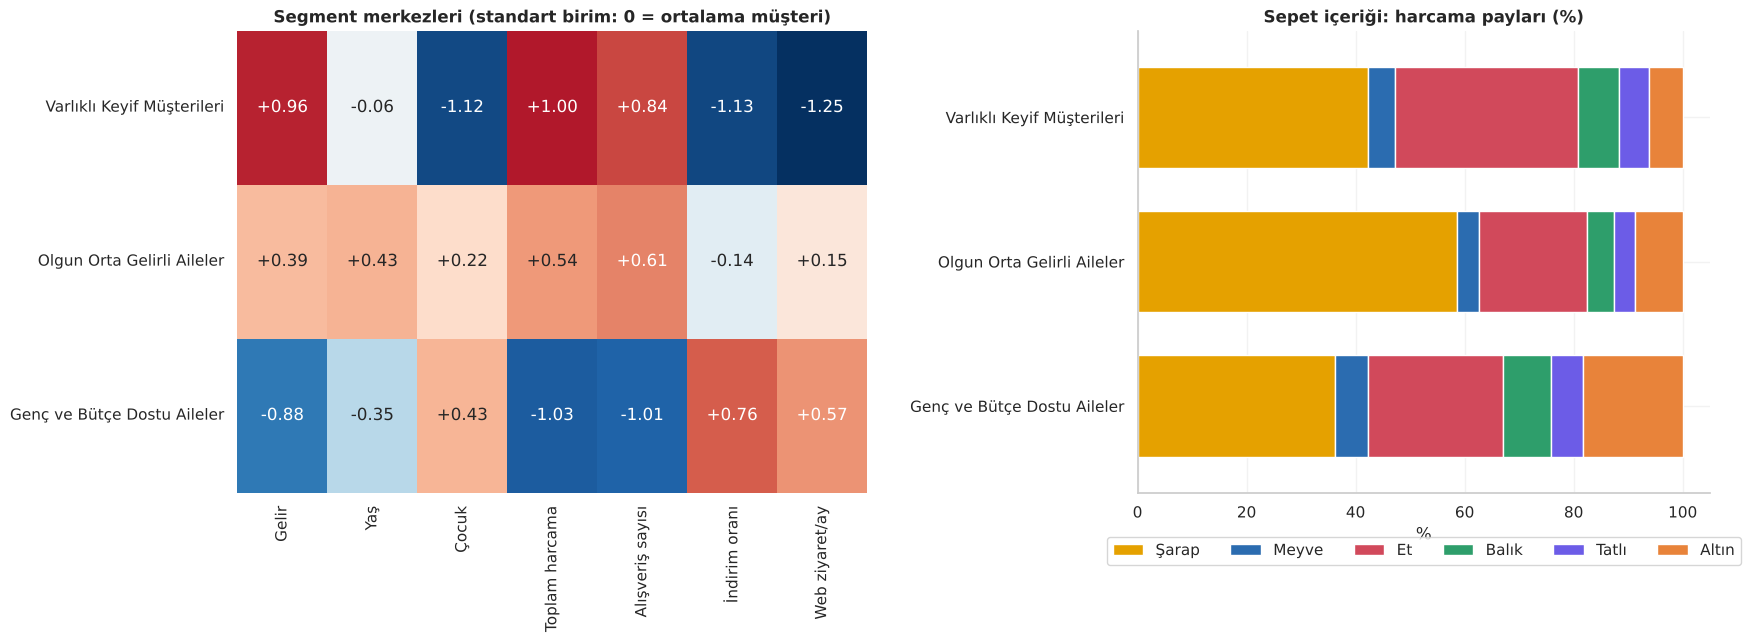

In [24]:
# Ad kuralının profile uyduğunu otomatik kontrol et (yanlış etiketlemeye karşı sigorta)
if K == 3:
    p = profil
    kontrol = {"Varlıklı: en yüksek gelir ve harcama": p["Gelir"].idxmax() == ADLAR3[0] and p["Toplam harcama"].idxmax() == ADLAR3[0],
               "Varlıklı: en az çocuk": p["Çocuk"].idxmin() == ADLAR3[0],
               "Olgun: en yaşlı": p["Yaş"].idxmax() == ADLAR3[1],
               "Olgun: en çok ergen çocuk": p["Ergen"].idxmax() == ADLAR3[1],
               "Olgun: gelir ortada": p["Gelir"].rank().loc[ADLAR3[1]] == 2,
               "Genç bütçe: en düşük gelir": p["Gelir"].idxmin() == ADLAR3[2],
               "Genç bütçe: en genç": p["Yaş"].idxmin() == ADLAR3[2],
               "Genç bütçe: en çok küçük çocuk": p["Küçük çocuk"].idxmax() == ADLAR3[2]}
    display(pd.Series(kontrol, name="Profil uyuyor mu?").to_frame())

fig, ax = plt.subplots(1, 2, figsize=(19, 6), gridspec_kw={"width_ratios": [1.1, 1]})
zprof = pd.DataFrame(Ztr, columns=SUTUN).groupby(seg_tr).mean()[KUME_OZELLIKLERI].loc[sira]; zprof.index = [SEG_KISA[j] for j in sira]
sns.heatmap(zprof, annot=True, fmt="+.2f", cmap="RdBu_r", center=0, ax=ax[0], cbar=False)
ax[0].set(title="Segment merkezleri (standart birim: 0 = ortalama müşteri)", ylabel="")
pay = profil[[f"{v} payı" for v in URUN_TR.values()]].copy(); pay.columns = list(URUN_TR.values()); pay.index = [SEG_KISA[j] for j in sira]
pay.plot.barh(stacked=True, ax=ax[1], color=KUME_RENK[:6], width=.7); ax[1].set(title="Sepet içeriği: harcama payları (%)", xlabel="%")
ax[1].legend(ncol=6, loc="upper center", bbox_to_anchor=(.5, -.08)); ax[1].invert_yaxis(); ax[1].set_ylabel("")
fig.subplots_adjust(wspace=.45)
kaydet(fig, "11_segment_kimligi"); plt.show()

### 🌳 11.2 · Vekil Karar Ağacı: Segmentleri Kurala Çevirmek

Pazarlama ekibi "merkeze uzaklık" ile çalışmaz; **kural** ister. Segment etiketlerini **ham özelliklerden** tahmin eden sığ bir karar ağacı (derinlik 3) kuruyoruz. **Sadakat (fidelity)**: ağacın, kümeleyicinin verdiği segmenti ne sıklıkla doğru söylediği. Sadakati **test** müşterilerinde ölçüyoruz.

Vekil ağacın sadakati — eğitim: %92.8 | test: %90.8
|--- Alışveriş sayısı <= 8.50
|   |--- Gelir <= 48822.00
|   |   |--- İndirim oranı <= 0.15
|   |   |   |--- class: 🌱 Genç ve Bütçe Dostu Aileler
|   |   |--- İndirim oranı >  0.15
|   |   |   |--- class: 🌱 Genç ve Bütçe Dostu Aileler
|   |--- Gelir >  48822.00
|   |   |--- Toplam harcama <= 91.50
|   |   |   |--- class: 🌱 Genç ve Bütçe Dostu Aileler
|   |   |--- Toplam harcama >  91.50
|   |   |   |--- class: 🏡 Olgun Orta Gelirli Aileler
|--- Alışveriş sayısı >  8.50
|   |--- Çocuk <= 0.50
|   |   |--- Web ziyaret/ay <= 5.50
|   |   |   |--- class: 💎 Varlıklı Keyif Müşterileri
|   |   |--- Web ziyaret/ay >  5.50
|   |   |   |--- class: 🏡 Olgun Orta Gelirli Aileler
|   |--- Çocuk >  0.50
|   |   |--- Gelir <= 40685.00
|   |   |   |--- class: 🌱 Genç ve Bütçe Dostu Aileler
|   |   |--- Gelir >  40685.00
|   |   |   |--- class: 🏡 Olgun Orta Gelirli Aileler



💾 Kaydedildi → outputs/figures/12_vekil_agac.png


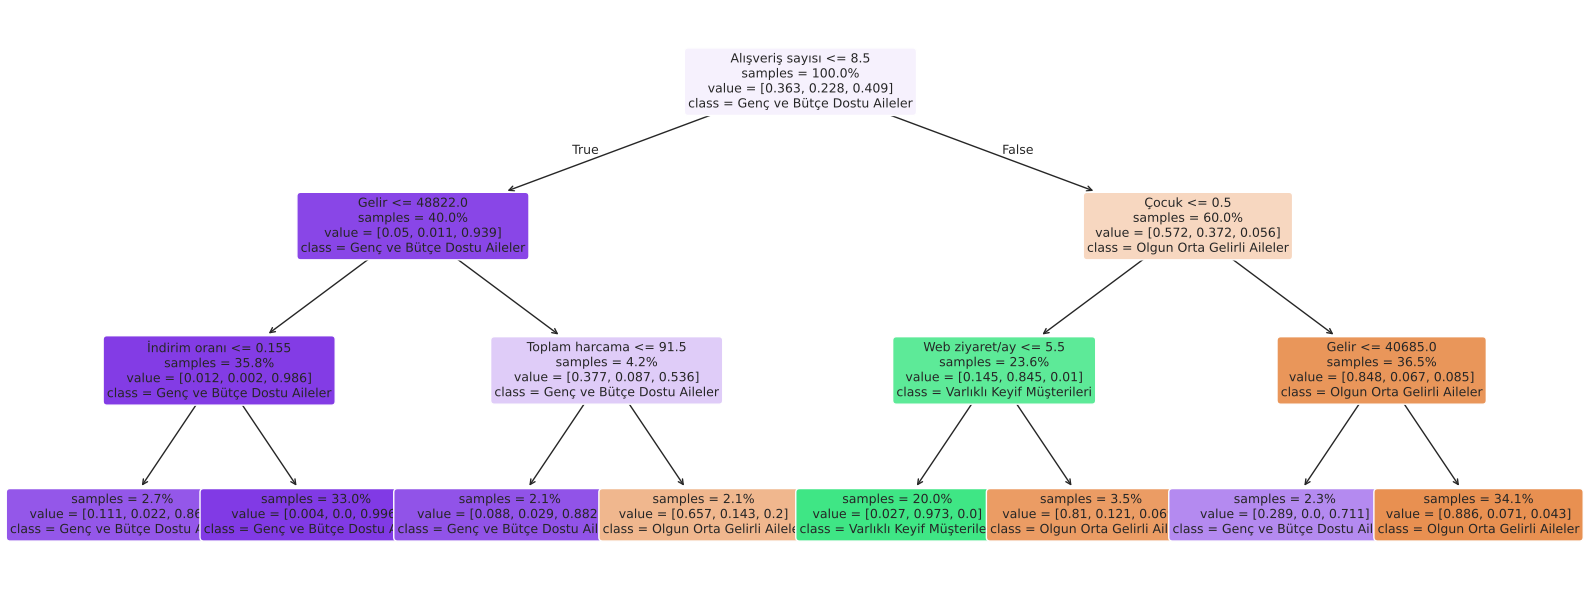

,Vekil ağaçta önem
Alışveriş sayısı,0.544
Çocuk,0.303
Web ziyaret/ay,0.077
Gelir,0.058
Toplam harcama,0.016
İndirim oranı,0.001
Yaş,0.000


📄 Rapor → outputs/reports/12_vekil_agac_onem.csv


In [25]:
Xtr_d = pd.DataFrame(SimpleImputer(strategy="median").fit(Xtr).transform(Xtr), columns=KUME_OZELLIKLERI)
Xte_d = pd.DataFrame(SimpleImputer(strategy="median").fit(Xtr).transform(Xte), columns=KUME_OZELLIKLERI)
seg_te = FINAL.predict(Xte) if hasattr(FINAL, "predict") else KNeighborsClassifier(15).fit(Ztr, seg_tr).predict(Zte)
agac = DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, random_state=RS).fit(Xtr_d, seg_tr)
sadakat_tr, sadakat_te = (agac.predict(Xtr_d) == seg_tr).mean(), (agac.predict(Xte_d) == seg_te).mean()
print(f"Vekil ağacın sadakati — eğitim: %{sadakat_tr * 100:.1f} | test: %{sadakat_te * 100:.1f}")
print(export_text(agac, feature_names=KUME_OZELLIKLERI, class_names=[SEGMENT_AD[c] for c in agac.classes_], decimals=2))
fig, ax = plt.subplots(figsize=(20, 7.5))
plot_tree(agac, feature_names=KUME_OZELLIKLERI, class_names=[SEG_KISA[c] for c in agac.classes_], filled=True, rounded=True,
          fontsize=9, ax=ax, impurity=False, proportion=True)
kaydet(fig, "12_vekil_agac"); plt.show()
onem = pd.Series(agac.feature_importances_, index=KUME_OZELLIKLERI).sort_values(ascending=False).round(3)
display(onem.to_frame("Vekil ağaçta önem")); rapor_kaydet(onem.to_frame("onem"), "12_vekil_agac_onem")

### 🎞️ 11.3 · Üç Boyutta Segmentler (Animasyon)

Haritanın ilk üç ekseninde segmentler dönerken: segmentlerin birbirine **değen ama karışmayan** bulutlar olduğuna dikkat edin.

🎞️ Animasyon → outputs/figures/13_segmentler_3b.gif


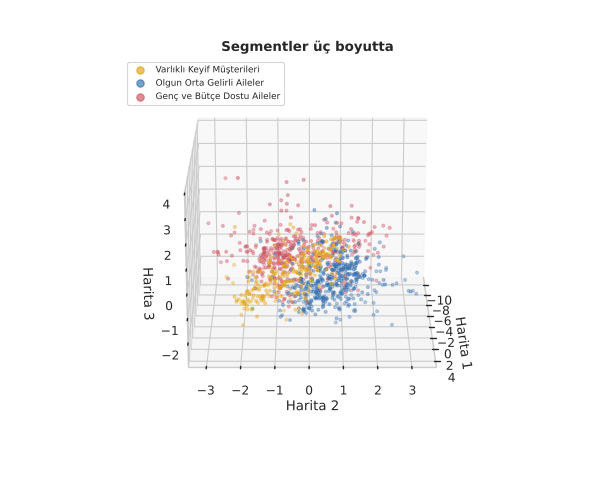

In [26]:
alt3 = np.random.default_rng(RS).choice(len(Ztr), 1100, replace=False)
def kare(i, fig):
    ax = fig.add_subplot(1, 1, 1, projection="3d")
    for j in sira:
        m = seg_tr[alt3] == j
        ax.scatter(Htr[alt3][m, 0], Htr[alt3][m, 1], Htr[alt3][m, 2], s=7, alpha=.65, color=KUME_RENK[sira.index(j)], label=SEG_KISA[j])
    ax.view_init(elev=20, azim=i * 10); ax.set_xlabel("Harita 1"); ax.set_ylabel("Harita 2"); ax.set_zlabel("Harita 3")
    ax.legend(loc="upper left", fontsize=8, markerscale=2.5); ax.set_title("Segmentler üç boyutta")
gif_kaydet(kare, 36, "13_segmentler_3b", figsize=(7.5, 6), fps=8)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Isı haritası ve vekil ağaç **aynı hikâyeyi** anlatıyor: ağacın ilk sorusu **"iki yılda 8'den fazla alışveriş yaptı mı?"** (aktif ve varlıklı kesim ↔ az alışveriş yapan genç aileler), ikinci sorusu **"evde çocuk var mı?"** (çocuksuz varlıklılar ↔ çocuklu olgun aileler). **Varlıklı keyif müşterileri** gelir ve harcamada en üstte, indirime en az başvuran ve **katalog** payı en yüksek grup; sepetlerinde **et** ortalamanın belirgin üstünde. **Olgun orta gelirli aileler** en yaşlı, ergen çocuklu ve en eski müşteriler; sepetin yaklaşık **%59'u şarap**, **web** alışverişi payı en yüksek. **Genç ve bütçe dostu aileler** küçük çocuklu, en düşük gelirli; **indirimli işlem** oranı ve **web ziyareti** en yüksek, ama alışverişlerini çoğunlukla **mağazadan** yapıyorlar; sepette **altın ürün** payı belirgin biçimde yüksek. Ağacın test sadakati %90 civarında: segmentleri pazarlama ekibine **birkaç basit kuralla** anlatabiliriz.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/proje_12.svg" width="100%" alt="Bölüm 12: Test seti">
</p>


### 🏆 12.1 · Test Seti Açılıyor (Tek Sefer)

Final boru hattını kilitli test müşterilerine **bir kez** uyguluyoruz ve dört soruya bakıyoruz:

1. **Sıkılık:** test silüeti eğitime yakın mı?
2. **Boy:** segment payları eğitimdekiyle aynı mı? (ki-kare testi)
3. **Yeniden keşif:** aynı algoritmayı testte **sıfırdan** kurunca, eğitimden atanan segmentleri yeniden buluyor mu? (ARI)
4. **Kimlik:** segmentlerin medyan profilleri testte de aynı mı?

In [27]:
Zte_f = FINAL.named_steps["on"].transform(Xte); Ztr_f = FINAL.named_steps["on"].transform(Xtr)
sil_tr, sil_te = silhouette_score(Ztr_f, seg_tr), silhouette_score(Zte_f, seg_te)
yeni = clone(FINAL_KUMELEYICI).fit_predict(Zte_f)
tab = pd.crosstab(np.r_[np.zeros(len(seg_tr)), np.ones(len(seg_te))], np.r_[seg_tr, seg_te])
p_ki = stats.chi2_contingency(tab)[1]
test_ozet = pd.DataFrame({"Eğitim": [sil_tr, davies_bouldin_score(Ztr_f, seg_tr), calinski_harabasz_score(Ztr_f, seg_tr)],
                          "Test": [sil_te, davies_bouldin_score(Zte_f, seg_te), calinski_harabasz_score(Zte_f, seg_te)]},
                         index=["Silüet ↑", "Davies-Bouldin ↓", "Calinski-Harabasz ↑ (n'e bağlı)"]).round(3)
display(test_ozet); rapor_kaydet(test_ozet, "13_test_olcutleri")
paylar = pd.DataFrame({"Eğitim %": pd.Series(seg_tr).value_counts(normalize=True), "Test %": pd.Series(seg_te).value_counts(normalize=True)}).mul(100).round(1)
paylar.index = [SEGMENT_AD[j] for j in paylar.index]; display(paylar)
ari_yeni = adjusted_rand_score(seg_te, yeni)
display(Markdown(f"**Okuma:** test silüeti **{sil_te:.3f}** (eğitim {sil_tr:.3f}); segment payları için ki-kare p = **{p_ki:.3f}** "
                 f"({'payların farklı olduğuna dair kanıt yok' if p_ki > .05 else 'paylar farklı!'}); testte sıfırdan kurulan modelle uyum ARI = **{ari_yeni:.3f}**."))

,Eğitim,Test
Silüet ↑,0.274,0.275
Davies-Bouldin ↓,1.278,1.298
Calinski-Harabasz ↑ (n'e bağlı),864.585,214.533


📄 Rapor → outputs/reports/13_test_olcutleri.csv


,Eğitim %,Test %
🌱 Genç ve Bütçe Dostu Aileler,40.9,37.5
🏡 Olgun Orta Gelirli Aileler,36.3,36.5
💎 Varlıklı Keyif Müşterileri,22.8,26.0


**Okuma:** test silüeti **0.275** (eğitim 0.274); segment payları için ki-kare p = **0.291** (payların farklı olduğuna dair kanıt yok); testte sıfırdan kurulan modelle uyum ARI = **0.864**.

Eğitim medyanı                               \
Segment        🌱 Genç ve Bütçe Dostu Aileler 🏡 Olgun Orta Gelirli Aileler   
Özellik                                                                     
Gelir                               33179.50                     57989.50   
Toplam harcama                         57.00                       660.00   
Web ziyaret/ay                          7.00                         6.00   
Yaş                                    40.00                        50.00   
Çocuk                                   1.00                         1.00   
İndirim oranı                           0.25                         0.15   

                                                             Test medyanı  \
Segment        💎 Varlıklı Keyif Müşterileri 🌱 Genç ve Bütçe Dostu Aileler   
Özellik                                                                     
Gelir                              77261.50                      31928.00   
Toplam harcama                      1290.00                         49.00   
Web ziyaret/ay                         2.00                          7.00   
Yaş                                   43.00                         40.50   
Çocuk                                  0.00                          1.00   
İndirim oranı                          0.05                          0.25   

                                                                          
Segment        🏡 Olgun Orta Gelirli Aileler 💎 Varlıklı Keyif Müşterileri  
Özellik                                                                   
Gelir                              57934.50                     76234.00  
Toplam harcama                       590.50                      1371.00  
Web ziyaret/ay                         6.00                         2.00  
Yaş                                   51.00                        46.00  
Çocuk                                  1.00                         0.00  
İndirim oranı                          0.15                         0.05

📄 Rapor → outputs/reports/14_egitim_test_profil.csv


💾 Kaydedildi → outputs/figures/15_test_seti.png


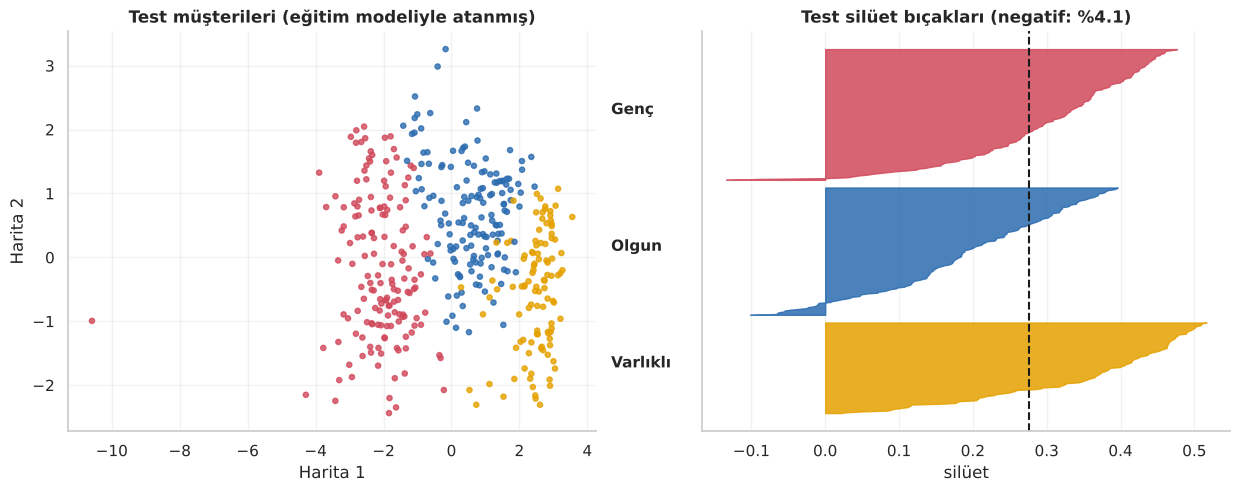

In [28]:
kars = []
for j in sira:
    for s in ["Gelir", "Yaş", "Çocuk", "Toplam harcama", "İndirim oranı", "Web ziyaret/ay"]:
        kars.append({"Segment": SEGMENT_AD[j], "Özellik": s, "Eğitim medyanı": tr.loc[seg_tr == j, s].median(), "Test medyanı": te.loc[seg_te == j, s].median()})
kars = pd.DataFrame(kars).pivot(index="Özellik", columns="Segment")
display(kars.round(2)); rapor_kaydet(kars.round(3), "14_egitim_test_profil")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
ax[0].scatter(Hte[:, 0], Hte[:, 1], s=14, c=[KUME_RENK[sira.index(j)] for j in seg_te], alpha=.8)
ax[0].set(title="Test müşterileri (eğitim modeliyle atanmış)", xlabel="Harita 1", ylabel="Harita 2")
st = silhouette_samples(Zte_f, seg_te); y0 = 5
for j in sira:
    s_ = np.sort(st[seg_te == j]); ax[1].fill_betweenx(np.arange(y0, y0 + len(s_)), 0, s_, color=KUME_RENK[sira.index(j)], alpha=.85)
    ax[1].text(-.29, y0 + len(s_) / 2, SEG_TEK[j], fontsize=11, fontweight="bold"); y0 += len(s_) + 8
ax[1].axvline(st.mean(), color="k", ls="--"); ax[1].set(title=f"Test silüet bıçakları (negatif: %{(st < 0).mean() * 100:.1f})", xlabel="silüet", yticks=[])
kaydet(fig, "15_test_seti"); plt.show()

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Segmentler **yalnızca eğitim verisinin bir tesadüfü değil**: test müşterilerinde benzer sıkılıkta, benzer paylarla ve benzer profillerle yeniden ortaya çıkıyor. Silüetin mutlak değeri (≈ 0,25–0,30) "kitap örneği" kadar yüksek değil; gerçek müşteri verisinde segmentler **birbirine değen bulutlardır**. Bu yüzden sınırdaki müşteriler (negatif silüet) 14. bölümde ayrıca ele alınacak.

</td></tr></table>

<a id="p13"></a>

<p align="center">
  <img src="assets/proje_13.svg" width="100%" alt="Bölüm 13: İş analizi">
</p>


### 💶 13.1 · Dış Doğrulama: Segmentler Kampanyaya Farklı mı Yanıt Veriyor?

Kampanya yanıtı kümelemede **hiç kullanılmadı**. Eğer segmentler yanıt oranında **anlamlı biçimde ayrışıyorsa**, segmentasyonun iş açısından gerçek bir şeyi yakaladığına dair **bağımsız bir kanıt** elde ederiz.

**Kâr eşiği:** veri setindeki sabit sütunlar iletişim maliyetini **3**, yanıt başına geliri **11** birim olarak verir *(vaka çalışmasının yorumu; varsayım)*. Bir müşteriye ulaşmak ancak yanıt olasılığı **3 / 11 ≈ %27,3**'ün üzerindeyse kâr getirir.

<p align="center">
  <img src="assets/diyagram_segment_karari.svg" width="100%" alt="Segmentten aksiyona">
</p>

,Veri,Segment,Müşteri,Yanıt oranı %,Alt %95,Üst %95,Kaldıraç (lift),Kişi başı beklenen kâr,Harcama payı %
0,Eğitim,💎 Varlıklı Keyif Müşterileri,374,25.67,21.50,30.33,1.69,-0.18,49.56
1,Eğitim,🏡 Olgun Orta Gelirli Aileler,597,12.90,10.44,15.83,0.85,-1.58,44.63
2,Eğitim,🌱 Genç ve Bütçe Dostu Aileler,672,11.46,9.27,14.09,0.75,-1.74,5.81
3,Test,💎 Varlıklı Keyif Müşterileri,107,29.91,22.05,39.16,1.95,0.29,54.74
4,Test,🏡 Olgun Orta Gelirli Aileler,150,13.33,8.80,19.70,0.87,-1.53,41.11
5,Test,🌱 Genç ve Bütçe Dostu Aileler,154,7.14,4.03,12.34,0.47,-2.21,4.15


📄 Rapor → outputs/reports/15_yanit_segment.csv


**Kâr eşiği: %27.3.** Eğitimde segment × yanıt ki-kare p = **9.7e-10** · Cramér V = **0.159**.

💾 Kaydedildi → outputs/figures/16_yanit_ve_ciro.png


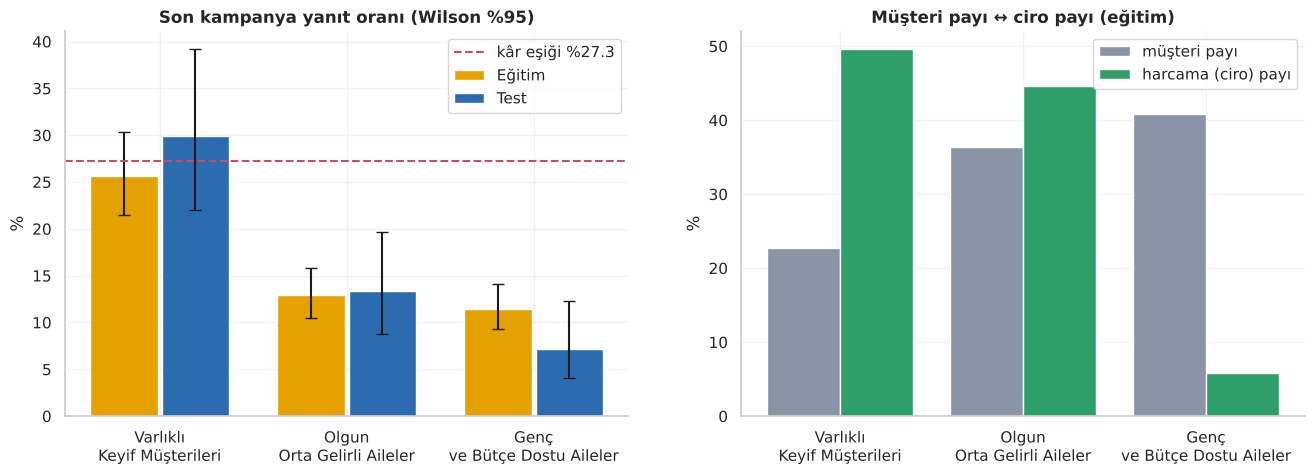

In [29]:
MALIYET, GELIR = float(ham["Z_CostContact"].iloc[0]), float(ham["Z_Revenue"].iloc[0]); ESIK = MALIYET / GELIR
satir = []
for ad_, df_, seg_ in [("Eğitim", tr, seg_tr), ("Test", te, seg_te)]:
    for j in sira:
        m = seg_ == j; y = df_.loc[m, "Son kampanya yanıtı"]; lo, hi = wilson(y.sum(), len(y))
        satir.append({"Veri": ad_, "Segment": SEGMENT_AD[j], "Müşteri": int(m.sum()), "Yanıt oranı %": y.mean() * 100, "Alt %95": lo * 100, "Üst %95": hi * 100,
                      "Kaldıraç (lift)": y.mean() / df_["Son kampanya yanıtı"].mean(), "Kişi başı beklenen kâr": GELIR * y.mean() - MALIYET,
                      "Harcama payı %": df_.loc[m, "Toplam harcama"].sum() / df_["Toplam harcama"].sum() * 100})
yanit = pd.DataFrame(satir); display(yanit.round(2)); rapor_kaydet(yanit.round(3), "15_yanit_segment", index=False)
p_yanit = stats.chi2_contingency(pd.crosstab(seg_tr, tr["Son kampanya yanıtı"]))[1]
display(Markdown(f"**Kâr eşiği: %{ESIK * 100:.1f}.** Eğitimde segment × yanıt ki-kare p = **{p_yanit:.2g}** · Cramér V = **{cramers_v(seg_tr, tr['Son kampanya yanıtı']):.3f}**."))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for i, (v, g) in enumerate(yanit.groupby("Veri", sort=False)):
    x = np.arange(len(g)) + (i - .5) * .38
    ax[0].bar(x, g["Yanıt oranı %"], width=.36, color=[RENK["altin"], RENK["mavi"]][i], label=v)
    ax[0].errorbar(x, g["Yanıt oranı %"], yerr=[g["Yanıt oranı %"] - g["Alt %95"], g["Üst %95"] - g["Yanıt oranı %"]], fmt="none", ecolor="k", capsize=4)
ax[0].axhline(ESIK * 100, color=RENK["pembe"], ls="--", label=f"kâr eşiği %{ESIK * 100:.1f}"); ax[0].set_xticks(range(len(sira)))
ax[0].set_xticklabels([SEG_KISA[j].replace(" ", "\n", 1) for j in sira]); ax[0].set(title="Son kampanya yanıt oranı (Wilson %95)", ylabel="%"); ax[0].legend()
gt = yanit[yanit["Veri"] == "Eğitim"].set_index("Segment")
ax[1].bar(np.arange(len(gt)) - .2, gt["Müşteri"] / gt["Müşteri"].sum() * 100, width=.4, color=RENK["gri"], label="müşteri payı")
ax[1].bar(np.arange(len(gt)) + .2, gt["Harcama payı %"], width=.4, color=RENK["yesil"], label="harcama (ciro) payı")
ax[1].set_xticks(range(len(gt))); ax[1].set_xticklabels([s.split(" ", 1)[1].replace(" ", "\n", 1) for s in gt.index]); ax[1].set(title="Müşteri payı ↔ ciro payı (eğitim)", ylabel="%"); ax[1].legend()
kaydet(fig, "16_yanit_ve_ciro"); plt.show()

### 🎯 13.2 · Hedefleme Kuralı: Eğitimde Seç, Testte Ölç

Hiçbir segment tek başına kâr eşiğini geçmeyebilir. Segmenti, kümelemede kullanmadığımız ama kampanyadan **önce bilinen** bir bilgiyle (**önceki 5 kampanyadan en az birini kabul etmiş mi?**) birleştirerek **alt segmentler** oluşturuyoruz. Kural: **eğitimde** yanıt oranının Wilson alt sınırı bile kâr eşiğinin üstünde olan alt segmentler hedeflenir. Sonra kural **testte bir kez** uygulanır ve "herkese gönder" stratejisiyle karşılaştırılır.

In [30]:
def alt_segment(df_, seg_):
    return pd.Series([f"{SEGMENT_AD[s].split(' ', 1)[1]} · {'eski kampanyacı' if k > 0 else 'yeni'}" for s, k in zip(seg_, df_["Önceki kampanya kabulü"])], index=df_.index)
alt_tr, alt_te = alt_segment(tr, seg_tr), alt_segment(te, seg_te)
egitim_alt = tr.groupby(alt_tr)["Son kampanya yanıtı"].agg(["sum", "count", "mean"])
egitim_alt["Wilson alt %"] = [wilson(s, n)[0] * 100 for s, n in zip(egitim_alt["sum"], egitim_alt["count"])]
egitim_alt["Hedefle?"] = egitim_alt["Wilson alt %"] > ESIK * 100
display(egitim_alt.rename(columns={"sum": "Yanıt", "count": "Müşteri", "mean": "Oran"}).round(3)); rapor_kaydet(egitim_alt.round(4), "16_alt_segment_kurali")
HEDEF = set(egitim_alt.index[egitim_alt["Hedefle?"]])

def strateji(df_, maske):
    n = int(maske.sum()); y = int(df_.loc[maske, "Son kampanya yanıtı"].sum())
    return {"Ulaşılan müşteri": n, "Yanıt": y, "Yanıt oranı %": 100 * y / max(n, 1), "Toplam kâr": GELIR * y - MALIYET * n,
            "Yakalanan yanıt payı %": 100 * y / df_["Son kampanya yanıtı"].sum()}
st_tab = pd.DataFrame({"Herkese gönder": strateji(te, pd.Series(True, index=te.index)),
                       "Segment + geçmiş kuralı": strateji(te, alt_te.isin(HEDEF)),
                       "Rastgele aynı sayıda": strateji(te, pd.Series(np.random.default_rng(RS).permutation(len(te)) < alt_te.isin(HEDEF).sum(), index=te.index))}).T
display(Markdown(f"**Hedeflenen alt segmentler (eğitimde seçildi):** {', '.join(sorted(HEDEF)) if HEDEF else 'yok'} — **test sonuçları:**")); display(st_tab.round(1))
rapor_kaydet(st_tab.round(2), "17_hedefleme_test")

,Yanıt,Müşteri,Oran,Wilson alt %,Hedefle?
Genç ve Bütçe Dostu Aileler · eski kampanyacı,28,61,0.459,34.013,True
Genç ve Bütçe Dostu Aileler · yeni,49,611,0.080,6.119,False
Olgun Orta Gelirli Aileler · eski kampanyacı,41,137,0.299,22.892,False
Olgun Orta Gelirli Aileler · yeni,36,460,0.078,5.706,False
Varlıklı Keyif Müşterileri · eski kampanyacı,70,151,0.464,38.593,True
Varlıklı Keyif Müşterileri · yeni,26,223,0.117,8.082,False


📄 Rapor → outputs/reports/16_alt_segment_kurali.csv


**Hedeflenen alt segmentler (eğitimde seçildi):** Genç ve Bütçe Dostu Aileler · eski kampanyacı, Varlıklı Keyif Müşterileri · eski kampanyacı — **test sonuçları:**

,Ulaşılan müşteri,Yanıt,Yanıt oranı %,Toplam kâr,Yakalanan yanıt payı %
Herkese gönder,411.0,63.0,15.3,-540.0,100.0
Segment + geçmiş kuralı,56.0,26.0,46.4,118.0,41.3
Rastgele aynı sayıda,56.0,9.0,16.1,-69.0,14.3


📄 Rapor → outputs/reports/17_hedefleme_test.csv


<table><tr><td>

<img src="assets/etiket_ybs.svg" height="34" alt="YBS Bağlantısı">

Bu bölüm, bir **müşteri ilişkileri yönetimi (CRM)** sisteminin kalbidir: segment kimliği müşteri kartına bir alan olarak yazılır, kampanya yönetim modülü hedef listesini **segment + geçmiş davranış** kuralıyla üretir, sonuçlar (yanıt, kâr) tekrar sisteme döner ve segmentasyon periyodik olarak yeniden değerlendirilir. Kümeleme bir kez yapılıp unutulan bir analiz değil, **karar destek döngüsünün** bir parçasıdır.

</td></tr></table>

### 🗺️ 13.3 · Segmente Özel Pazarlama Önerileri

Aşağıdaki öneriler **bu notebook'taki profil ve yanıt tablolarından** türetilmiştir; uygulanmadan önce **A/B testiyle** doğrulanmalıdır.

In [31]:
oneri = []
for j in sira:
    p = profil.loc[SEGMENT_AD[j]]; y = yanit[(yanit["Veri"] == "Eğitim") & (yanit["Segment"] == SEGMENT_AD[j])].iloc[0]
    genel = tr[pay_sut].mean() * 100                                  # ortalama müşterinin payları
    kanal = max(["Web payı", "Katalog payı", "Mağaza payı"], key=lambda c: p[c] / genel[c]).replace(" payı", "")
    urun_ = max([f"{v} payı" for v in URUN_TR.values()], key=lambda c: p[c] / genel[c]).replace(" payı", "")
    oneri.append({"Segment": SEGMENT_AD[j], "Müşteri payı %": round(p["Müşteri payı %"], 1), "Ciro payı %": round(y["Harcama payı %"], 1),
                  "Medyan gelir": int(p["Gelir"]), "Medyan harcama": int(p["Toplam harcama"]), "Öne çıkan ürün (ortalamaya göre)": urun_, "Öne çıkan kanal (ortalamaya göre)": kanal,
                  "İndirimli işlem %": round(p["İndirim oranı"] * 100, 1), "Yanıt oranı %": round(y["Yanıt oranı %"], 1)})
oneri = pd.DataFrame(oneri).set_index("Segment"); display(oneri); rapor_kaydet(oneri, "18_segment_ozet")

,Müşteri payı %,Ciro payı %,Medyan gelir,Medyan harcama,Öne çıkan ürün (ortalamaya göre),Öne çıkan kanal (ortalamaya göre),İndirimli işlem %,Yanıt oranı %
Segment,,,,,,,,
💎 Varlıklı Keyif Müşterileri,22.8,49.6,77261,1290,Et,Katalog,5.0,25.7
🏡 Olgun Orta Gelirli Aileler,36.3,44.6,57989,660,Şarap,Web,14.8,12.9
🌱 Genç ve Bütçe Dostu Aileler,40.9,5.8,33179,57,Altın,Mağaza,25.0,11.5


📄 Rapor → outputs/reports/18_segment_ozet.csv


| Segment | Ne yapalım? | Neden? (tablolara dayanarak) |
|:--|:--|:--|
| 💎 **Varlıklı Keyif Müşterileri** | Premium et & şarap seçkisi, **katalog + kişisel teklif**; indirim değil **ayrıcalık** dili; sadakat programının üst kademesi. **Önceki kampanyaları kabul edenler** öncelikli hedef | Müşterilerin ≈ %23'ü, cironun ≈ yarısı; en yüksek yanıt oranı; indirimli işlem payı en düşük; katalog payı en yüksek |
| 🏡 **Olgun Orta Gelirli Aileler** | **Şarap kulübü / şarap ayı** kampanyası, web'de aile paketleri; ergen çocuklu hane için toplu alım; uzun süreli müşteri olduklarına **teşekkür eden** sadakat mesajı | Ciroda ikinci büyük pay; sepetin ≈ %59'u şarap; web alışverişi payı en yüksek; en eski müşteriler |
| 🌱 **Genç ve Bütçe Dostu Aileler** | **Düşük maliyetli dijital** iletişim (uygulama bildirimi, e-posta) ile **mağazaya kupon**; temel ihtiyaç ve çocuk ürünleri; pahalı katalog **gönderilmemeli**. Yalnızca **eski kampanyacı** alt grubu hedeflenmeli | En düşük gelir/harcama; indirim oranı ve web ziyareti en yüksek ama alışveriş mağazada; segmentin geneli kâr eşiğinin çok altında, eski kampanyacı alt grubunda yanıt ≈ %46 |

<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Maliyet (3) ve gelir (11) sayıları vaka çalışmasından gelen **varsayımlardır**; gerçek bir işletmede kampanya maliyeti, marj ve müşteri yaşam boyu değeri **finans ekibiyle** birlikte hesaplanmalıdır. "Bütçe dostu" segmente daha az teklif göndermek kâr açısından mantıklı olabilir; ama **fırsatları sistematik olarak düşük gelirli müşterilerden esirgemek** sonucunu doğurmamalı (bkz. 14. bölüm).

</td></tr></table>

<a id="p14"></a>

<p align="center">
  <img src="assets/proje_14.svg" width="100%" alt="Bölüm 14: Adalet ve hata">
</p>


### ⚖️ 14.1 · Segmentler Hassas Özelliklerin Vekili mi?

Eğitim ve medeni durum kümelemede **kullanılmadı**; **yaş** ise kullanıldı. Segmentler bu özelliklerle ne kadar ilişkili (Cramér V)? Ve yaşı tamamen çıkarırsak segmentler ne kadar değişir?

,Cramér V
Eğitim (kullanılmadı),0.153
Medeni durum (kullanılmadı),0.110
Yaş bandı (KULLANILDI),0.273


💾 Kaydedildi → outputs/figures/17_hassas_ozellikler.png


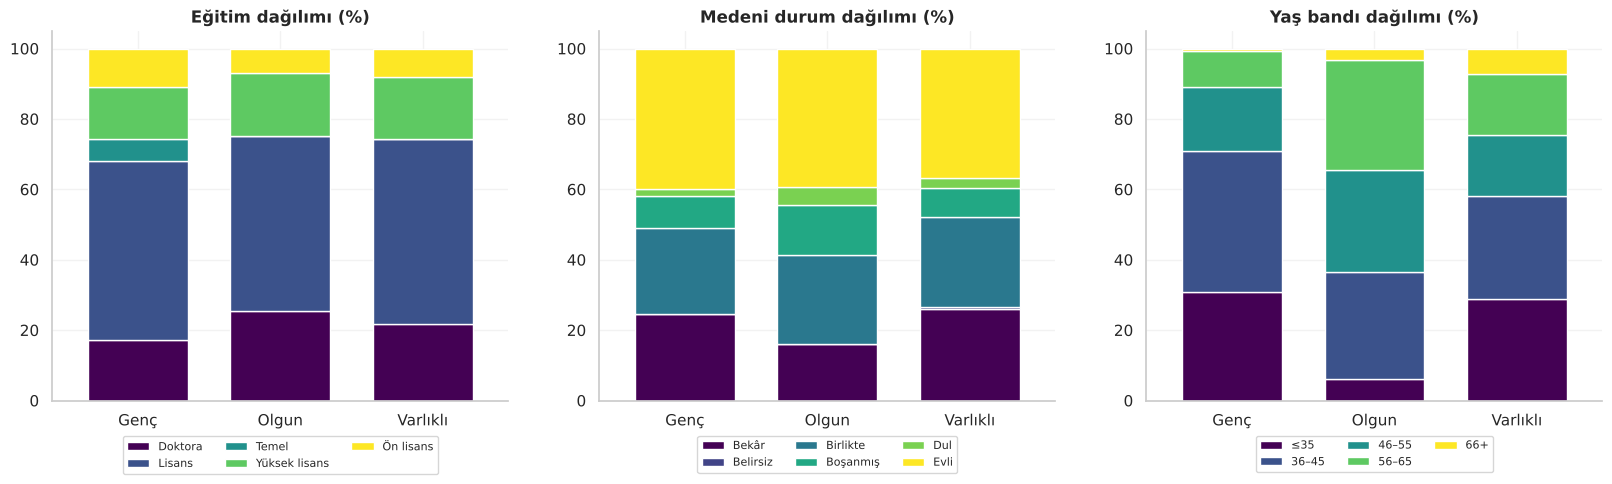

**Yaş çıkarılınca:** segmentlerin yaşlı segmentasyonla uyumu ARI = **0.813**; yaş bandıyla ilişki V = **0.202** (önce 0.273); kampanya yanıtıyla ilişki V = **0.168** (önce 0.159).

📄 Rapor → outputs/reports/19_hassas_ozellikler.csv


In [32]:
yas_bant = pd.cut(tr["Yaş"], [0, 35, 45, 55, 65, 120], labels=["≤35", "36–45", "46–55", "56–65", "66+"])
hassas = pd.DataFrame({"Cramér V": [cramers_v(seg_tr, tr["Eğitim"]), cramers_v(seg_tr, tr["Medeni durum"]), cramers_v(seg_tr, yas_bant)]},
                      index=["Eğitim (kullanılmadı)", "Medeni durum (kullanılmadı)", "Yaş bandı (KULLANILDI)"]).round(3)
display(hassas)
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
for a, (ad_, s) in zip(ax, [("Eğitim", tr["Eğitim"]), ("Medeni durum", tr["Medeni durum"]), ("Yaş bandı", yas_bant)]):
    ct = pd.crosstab(pd.Series([SEG_TEK[j] for j in seg_tr], name="Segment"), s, normalize="index") * 100
    ct.plot.bar(stacked=True, ax=a, colormap="viridis", width=.7, legend=True); a.set(title=f"{ad_} dağılımı (%)", xlabel=""); a.tick_params(axis="x", rotation=0)
    a.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.08), ncol=3)
kaydet(fig, "17_hassas_ozellikler"); plt.show()

# Yaşsız segmentasyon: aynı boru hattı, yaş sütunu olmadan
ozel_yassiz = [s for s in KUME_OZELLIKLERI if s != "Yaş"]
ct_y = ColumnTransformer([("log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(log1p_donustur)), LOG_SUTUNLARI)], remainder="passthrough")
yassiz = Pipeline([("on", ct_y), ("olcek", StandardScaler()), ("kume", clone(FINAL_KUMELEYICI))]).fit(tr[ozel_yassiz])
seg_y = yassiz.predict(tr[ozel_yassiz]) if hasattr(yassiz, "predict") else yassiz.named_steps["kume"].labels_
display(Markdown(f"**Yaş çıkarılınca:** segmentlerin yaşlı segmentasyonla uyumu ARI = **{adjusted_rand_score(seg_tr, seg_y):.3f}**; "
                 f"yaş bandıyla ilişki V = **{cramers_v(seg_y, yas_bant):.3f}** (önce {hassas.iloc[2, 0]:.3f}); "
                 f"kampanya yanıtıyla ilişki V = **{cramers_v(seg_y, tr['Son kampanya yanıtı']):.3f}** (önce {cramers_v(seg_tr, tr['Son kampanya yanıtı']):.3f})."))
rapor_kaydet(hassas, "19_hassas_ozellikler")

<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Yaş, segmentlerden birinin adında ("genç") bile geçiyor; yani segmentasyon **yaşla açıkça ilişkili**. Bu kendi başına yasak değildir (yaşam evresi pazarlamanın meşru bir boyutudur) ama iki risk doğurur: (1) **fiyat ve fırsat ayrımcılığı** (ör. bir yaş grubuna sistematik olarak daha pahalı teklif), (2) yasal düzenlemelerde (ör. KVKK/GDPR profil oluşturma hükümleri) açıklanabilirlik yükümlülüğü. Yaşsız segmentasyon deneyi, yaşı çıkarmanın segment yapısını ve iş değerini **ne kadar değiştirdiğini** ölçerek karar vericiye **şeffaf bir seçenek** sunar.

</td></tr></table>

### 🧭 14.2 · Sınırdaki ve Sıra Dışı Müşteriler

**Sınırdaki müşteri:** silüeti negatif (komşu segmente daha yakın) → kampanyada **iki segmentin mesajı** da denenebilir. **Sıra dışı müşteri:** merkezine uzaklığı eğitimdeki uzaklıkların **%99'luk diliminin** üstünde → segment ataması güvenilmez, **insan incelemesine** gider.

In [33]:
if hasattr(FINAL, "transform") and hasattr(FINAL.named_steps["kume"], "cluster_centers_"):
    uz_tr, uz_te = FINAL.transform(Xtr).min(1), FINAL.transform(Xte).min(1)
else:                                                             # merkez yoksa: segment ortalamasına uzaklık
    M = np.array([Ztr_f[seg_tr == j].mean(0) for j in range(K)])
    uz_tr = np.sqrt(((Ztr_f - M[seg_tr]) ** 2).sum(1)); uz_te = np.sqrt(((Zte_f - M[seg_te]) ** 2).sum(1))
AYKIRI_ESIK = float(np.quantile(uz_tr, 0.99))
s_te = silhouette_samples(Zte_f, seg_te)
hata = pd.DataFrame({"Segment": [SEGMENT_AD[j] for j in seg_te], "Sınırda (silüet<0)": s_te < 0, "Sıra dışı": uz_te > AYKIRI_ESIK})
hata_ozet = hata.groupby("Segment")[["Sınırda (silüet<0)", "Sıra dışı"]].mean().mul(100).round(1)
display(hata_ozet); rapor_kaydet(hata_ozet, "20_sinirdaki_siradisi")
print(f"Sıra dışı eşiği (eğitim %99): {AYKIRI_ESIK:.3f} | testte sıra dışı: {int(hata['Sıra dışı'].sum())} müşteri")
siradisi = te.loc[hata["Sıra dışı"].to_numpy(), KUME_OZELLIKLERI].assign(Segment=hata.loc[hata["Sıra dışı"], "Segment"].values, Uzaklık=uz_te[hata["Sıra dışı"].to_numpy()].round(2))
display(siradisi.sort_values("Uzaklık", ascending=False).head(8))

,Sınırda (silüet<0),Sıra dışı
Segment,,
🌱 Genç ve Bütçe Dostu Aileler,1.3,1.9
🏡 Olgun Orta Gelirli Aileler,10.0,0.7
💎 Varlıklı Keyif Müşterileri,0.0,0.9


📄 Rapor → outputs/reports/20_sinirdaki_siradisi.csv
Sıra dışı eşiği (eğitim %99): 3.802 | testte sıra dışı: 5 müşteri


,Gelir,Yaş,Çocuk,Toplam harcama,Alışveriş sayısı,İndirim oranı,Web ziyaret/ay,Segment,Uzaklık
22,1730.0,43,0,8,0,1.00,20,🌱 Genç ve Bütçe Dostu Aileler,10.76
180,156924.0,65,0,8,0,0.00,0,💎 Varlıklı Keyif Müşterileri,6.36
218,5305.0,38,1,32,1,0.00,13,🌱 Genç ve Bütçe Dostu Aileler,5.36
80,7144.0,48,2,416,25,0.00,0,🏡 Olgun Orta Gelirli Aileler,5.23
251,38285.0,55,3,10,3,0.25,2,🌱 Genç ve Bütçe Dostu Aileler,3.94


<table><tr><td>

<img src="assets/etiket_teshis.svg" height="34" alt="Teşhis">

Sınırdaki müşteriler (negatif silüet) beklendiği gibi **ortadaki** segmentte, yani **olgun orta gelirli ailelerde** yoğunlaşıyor: bu segmentin iki komşusu var. Sıra dışı müşterilere bakın: çoğunlukla **çok yüksek indirim oranı**, **çok fazla web ziyareti** ya da **gelirine göre olağandışı harcama** gibi tek bir uç özelliği olan müşteriler. Bunlar ya **ölçüm/veri hatası** ya da **gerçekten farklı** (ör. kurumsal alım yapan) müşterilerdir; her iki durumda da otomatik kampanyanın dışında tutulup incelenmeleri önerilir.

</td></tr></table>

<a id="p15"></a>

<p align="center">
  <img src="assets/proje_15.svg" width="100%" alt="Bölüm 15: Kayıt">
</p>

### 💾 15.1 · Modeli ve Meta Bilgiyi Kaydet

Final boru hattı (doldurma + log + ölçek + kümeleyici) **tek bir `joblib` dosyasına** kaydedilir. Yanına segment adları, özellik listesi, sıra dışı eşiği, başarı ölçütleri ve sürümler **`meta.json`** olarak yazılır.

In [34]:
MODEL_DIR = Path("outputs/model"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(FINAL, MODEL_DIR / "musteri_segment_model.joblib")
meta = {"proje": "Gün 55 — Müşteri segmentasyonu (K-Means ve 28 algoritma)", "model": FINAL_AD, "k": K,
        "ozellikler": KUME_OZELLIKLERI, "log_sutunlari": LOG_SUTUNLARI,
        "segment_adlari": {str(k): v for k, v in SEGMENT_AD.items()}, "aykiri_esik": AYKIRI_ESIK,
        "basari": {"egitim_siluet": round(float(sil_tr), 4), "test_siluet": round(float(sil_te), 4), "test_yeniden_kesif_ari": round(float(ari_yeni), 4),
                   "vekil_agac_test_sadakati": round(float(sadakat_te), 4)},
        "veri": {"kaynak": "Kaggle — Customer Personality Analysis (Patel, 2021)", "egitim": len(tr), "test": len(te)},
        "surumler": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
        "uyari": "Yalnızca bu veri setinin müşteri tanımları ve 2012–2014 dönemi için geçerlidir."}
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
# Ham sütunlu örnek müşteriler (testten 5 kişi) → işletmedeki gibi HAM kayıtla deneme yapılabilsin
ham_test = temiz.reset_index(drop=True).loc[TEST_IDX].reset_index(drop=True)
assert (ozellik_uret(ham_test)[KUME_OZELLIKLERI].fillna(-1).to_numpy() == te[KUME_OZELLIKLERI].fillna(-1).to_numpy()).all()   # aynı müşteriler mi?
ham_test.head(5).to_csv(MODEL_DIR / "ornek_musteriler.csv", index=False, encoding="utf-8-sig")
print("Kaydedilen dosyalar:", sorted(p.name for p in MODEL_DIR.iterdir()))
print(json.dumps(meta, ensure_ascii=False, indent=2)[:900])

Kaydedilen dosyalar: ['meta.json', 'musteri_segment_model.joblib', 'ornek_musteriler.csv']
{
  "proje": "Gün 55 — Müşteri segmentasyonu (K-Means ve 28 algoritma)",
  "model": "K-Medoids (n_init=10, max_iter=100)",
  "k": 3,
  "ozellikler": [
    "Gelir",
    "Yaş",
    "Çocuk",
    "Toplam harcama",
    "Alışveriş sayısı",
    "İndirim oranı",
    "Web ziyaret/ay"
  ],
  "log_sutunlari": [
    "Gelir",
    "Toplam harcama",
    "Alışveriş sayısı"
  ],
  "segment_adlari": {
    "1": "💎 Varlıklı Keyif Müşterileri",
    "0": "🏡 Olgun Orta Gelirli Aileler",
    "2": "🌱 Genç ve Bütçe Dostu Aileler"
  },
  "aykiri_esik": 3.8020390757087306,
  "basari": {
    "egitim_siluet": 0.2736,
    "test_siluet": 0.2754,
    "test_yeniden_kesif_ari": 0.8638,
    "vekil_agac_test_sadakati": 0.9075
  },
  "veri": {
    "kaynak": "Kaggle — Customer Personality Analysis (Patel, 2021)",
    "egitim": 1643,
    "test": 411
  },
  "surumler": {
    "python": "3.13.18",
    "scikit-learn": "1.9.1",
   


### 🧰 15.2 · Ayrı Süreçte Yükleme Testi

Kaydedilen model, bu notebook'un belleğinden **bağımsız** yeni bir Python sürecinde yüklenip **ham müşteri kaydıyla** çalıştırılıyor (işletmedeki gerçek kullanım).

In [35]:
betik = """
import pandas as pd
from musteri_yardimci import segment_ata
ham = pd.read_csv('outputs/model/ornek_musteriler.csv', encoding='utf-8-sig')
print(segment_ata(ham).to_string())
tek = ham.iloc[0].to_dict()
print('Tek müşteri:', segment_ata(tek).iloc[0].to_dict())
"""
sonuc = subprocess.run([sys.executable, "-c", betik], capture_output=True, text=True, cwd=".")
print(sonuc.stdout or sonuc.stderr)
# Aynı müşterilerin bu süreçteki tahminiyle karşılaştır
ayni = (FINAL.predict(ozellik_uret(ham_test.head(5))[KUME_OZELLIKLERI]) == segment_ata(ham_test.head(5), FINAL, meta)["Segment no"].to_numpy()).all()
print("Ayrı süreç ile bu süreç aynı segmenti veriyor mu?", bool(ayni))

   Segment no                        Segment  Merkeze uzaklık  Sıra dışı mı?
0           0   🏡 Olgun Orta Gelirli Aileler            1.697          False
1           2  🌱 Genç ve Bütçe Dostu Aileler            2.031          False
2           2  🌱 Genç ve Bütçe Dostu Aileler            1.549          False
3           0   🏡 Olgun Orta Gelirli Aileler            1.392          False
4           1   💎 Varlıklı Keyif Müşterileri            2.018          False
Tek müşteri: {'Segment no': 0, 'Segment': '🏡 Olgun Orta Gelirli Aileler', 'Merkeze uzaklık': 1.697, 'Sıra dışı mı?': False}

Ayrı süreç ile bu süreç aynı segmenti veriyor mu? True


<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Bu model **yalnızca bu market zincirinin 2012–2014 müşterileri ve bu özellik tanımları** için kuruldu. Farklı bir ülke, para birimi, dönem ya da ürün yelpazesinde segmentler **geçerliliğini yitirebilir**. İşletmede **izleme** kurulmalıdır: segment payları, merkezlere ortalama uzaklık ve sıra dışı müşteri oranı **aylık** izlenmeli; belirgin kayma görülürse segmentasyon yeniden yapılmalıdır.

</td></tr></table>

<a id="p16"></a>

<p align="center">
  <img src="assets/proje_16.svg" width="100%" alt="Bölüm 16: Proje özeti">
</p>

### 📋 16.1 · Proje Özeti (hücre çıktılarından üretilir)

In [36]:
y_tr = yanit[yanit["Veri"] == "Test"].set_index("Segment")["Yanıt oranı %"]
ozet = pd.DataFrame([
    ("Veri", f"{len(d)} müşteri (temiz), 7 kümeleme özelliği; eğitim {len(tr)} / test {len(te)}"),
    ("Segment sayısı (kural 1)", f"k = {K} (geometrik ölçütlerin tercihi k = {k_tablo['Silüet ↑'].idxmax()}; dirsek {DIZ})"),
    ("Yarış", f"{len(YARISCI) - 1} algoritma + taban; uygun: {int(yaris.drop('Rastgele taban')['Uygun'].sum())}, uygun değil: {int((~yaris.drop('Rastgele taban')['Uygun']).sum())}"),
    ("Yarış lideri (bileşik sıra)", f"{yaris.index[0]} — silüet {yaris.iloc[0]['Silüet']:.3f}, kararlılık {yaris.iloc[0]['Kararlılık (ARI)']:.3f}"),
    ("Final model (kural 3)", FINAL_AD),
    ("Silüet eğitim / test", f"{sil_tr:.3f} / {sil_te:.3f}"),
    ("Testte yeniden keşif (ARI)", f"{ari_yeni:.3f}"),
    ("Vekil ağaç test sadakati", f"%{sadakat_te * 100:.1f}"),
    ("Test yanıt oranları", " · ".join(f"{s.split(' ', 1)[1]}: %{v:.1f}" for s, v in y_tr.items())),
    ("Kâr eşiği", f"%{ESIK * 100:.1f}"),
    ("Hedefleme (test)", f"herkese: kâr {st_tab.loc['Herkese gönder', 'Toplam kâr']:.0f} · kural: kâr {st_tab.loc['Segment + geçmiş kuralı', 'Toplam kâr']:.0f} "
                         f"({st_tab.loc['Segment + geçmiş kuralı', 'Ulaşılan müşteri']:.0f} müşteri, yanıtların %{st_tab.loc['Segment + geçmiş kuralı', 'Yakalanan yanıt payı %']:.0f}'i)"),
    ("Yaş çıkarılınca uyum (ARI)", f"{adjusted_rand_score(seg_tr, seg_y):.3f}"),
], columns=["Başlık", "Sonuç"]).set_index("Başlık")
display(ozet); rapor_kaydet(ozet, "99_proje_ozeti")

,Sonuç
Başlık,
Veri,"2054 müşteri (temiz), 7 kümeleme özelliği; eği..."
Segment sayısı (kural 1),k = 3 (geometrik ölçütlerin tercihi k = 2; dir...
Yarış,"28 algoritma + taban; uygun: 18, uygun değil: 10"
Yarış lideri (bileşik sıra),"K-Medoids — silüet 0.274, kararlılık 0.870"
Final model (kural 3),"K-Medoids (n_init=10, max_iter=100)"
Silüet eğitim / test,0.274 / 0.275
Testte yeniden keşif (ARI),0.864
Vekil ağaç test sadakati,%90.8
Test yanıt oranları,Varlıklı Keyif Müşterileri: %29.9 · Olgun Orta...


📄 Rapor → outputs/reports/99_proje_ozeti.csv


<table><tr><td>

<img src="assets/etiket_yonetici.svg" height="34" alt="Yönetici Özeti">

Bu bölümdeki tablo, **bu çalıştırmanın gerçek sayılarıdır**. Yönetici için dört cümle: (1) Müşteriler **üç anlamlı segmente** ayrılıyor: varlıklı keyif müşterileri, olgun orta gelirli aileler ve genç bütçe dostu aileler; segmentler yeni müşterilerde de **aynı biçimde** ortaya çıkıyor. (2) Segmentler, kümelemede hiç kullanılmayan **kampanya yanıtında** belirgin biçimde ayrışıyor; varlıklı segment müşterilerin yaklaşık beşte biri olduğu hâlde cironun yaklaşık **yarısını** getiriyor ve kampanyaya en çok yanıt veren grup. (3) Toplu kampanya kâr eşiğinin altında kalıyor; **segment + geçmiş kampanya davranışı** ile seçilen küçük bir hedef kitle zararı belirgin biçimde azaltıyor ya da kâra çeviriyor (bkz. 13.2 test tablosu). (4) Segmentasyon yaşla ilişkili; yaşsız alternatif ölçüldü ve karar vericiye sunuldu.

</td></tr></table>

<p align="center">
  <img src="assets/kapanis_proje.svg" width="100%" alt="Kapanış">
</p>

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🔒</h3><b>Etiketsizken de test</b><br><sub><i>kilitli test · sızıntısız boru hattı</i></sub><br><br>Segmentlerin tesadüf olmadığını ancak <b>görülmemiş müşteri</b> gösterir<br><br></td><td width="33%" valign="top" align="center"><h3>🪤</h3><b>Silüet tuzağı</b><br><sub><i>boylara bak</i></sub><br><br>En yüksek silüet, tek dev segment + birkaç uç müşteri olabilir<br><br></td><td width="33%" valign="top" align="center"><h3>📏</h3><b>Sabit cetvel</b><br><sub><i>aynı ölçüm uzayı</i></sub><br><br>Farklı ön işlemelerin silüetleri <b>kıyaslanamaz</b>; ayarda uzay sabit kalmalı<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>🔁</h3><b>Kararlılık</b><br><sub><i>bootstrap · tohum</i></sub><br><br>Yeniden örneklemede kaybolan segment, pazarlama bütçesine değmez<br><br></td><td width="33%" valign="top" align="center"><h3>💶</h3><b>Dış doğrulama</b><br><sub><i>kullanılmayan bir hedefle</i></sub><br><br>Segmentler, görmedikleri <b>kampanya yanıtında</b> ayrışıyorsa iş değeri vardır<br><br></td><td width="33%" valign="top" align="center"><h3>⚖️</h3><b>Hassas özellikler</b><br><sub><i>vekil etkisi</i></sub><br><br>Kullanılmayan bir özellik bile segmentlere <b>sızabilir</b>; ölç ve raporla<br><br></td></tr>
</table>

### ❓ Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> Kümelemede "y" yokken neden test seti ayırdık?</summary>

Segmentlerin **eğitim verisine özgü bir tesadüf** olup olmadığını ancak görülmemiş müşterilerde (test silüeti, payların benzerliği, sıfırdan kurulan modelle uyum) anlayabiliriz. Ayrıca hedefleme kuralını eğitimde seçip testte **dürüstçe** ölçmek için gerekir.
</details>

<details><summary><b>2.</b> Tek bağlantılı hiyerarşik kümeleme en yüksek silüeti aldığı hâlde neden elendi?</summary>

Müşterilerin neredeyse tamamını tek bir segmente koyup birkaç uç müşteriyi ayrı "segment" yaptı. Silüet bu ayrıklığı ödüllendirir; ama **en küçük segment** şartı (≥ %5) bu sonucun iş için anlamsız olduğunu yakalar.
</details>

<details><summary><b>3.</b> Ölçeksiz ve ölçekli kümelemelerin silüetlerini neden doğrudan karşılaştırmadık?</summary>

Silüet mesafelerle hesaplanır; ön işleme mesafeleri değiştirir. Farklı uzaylarda hesaplanan silüetler **farklı cetvellerle** ölçülmüş gibidir. Onun yerine söz hakkı dengesi ve kararlılığa baktık; ayar sırasında da uzayı **sabit** tuttuk.
</details>

<details><summary><b>4.</b> Kampanya yanıtını kümelemeye özellik olarak ekleseydik ne olurdu?</summary>

Segmentler yanıtı "bilerek" oluşurdu; yanıt oranındaki farklar artık bağımsız bir kanıt olmazdı (**dış doğrulama** anlamını yitirirdi). Ayrıca yeni müşteride yanıt bilinmediği için segment ataması yapılamazdı.
</details>

<details><summary><b>5.</b> Bir segmentin silüeti negatif olan müşterileri için ne önerirsiniz?</summary>

Bu müşteriler iki segmentin sınırındadır: kampanyada **her iki segmentin mesajını** test etmek, segment atamasını "olasılıkla" vermek (ör. GMM ya da bulanık C-ortalamalar üyelikleri) veya bu müşterileri ayrı bir "kararsız" listesinde izlemek.
</details>

### 🏠 Ödevler

1. 6.1'deki ön işleme deneyine **`QuantileTransformer(output_distribution="normal")`** ekleyin; söz hakkı dengesi ve kararlılık nasıl değişiyor?
2. Kural 1'deki iş kısıtını kaldırın (k ≥ 2): seçilen k ve 13. bölümdeki yanıt farkları nasıl değişir?
3. Yarışa **Gaussian karışımda BIC ile k seçimi** (k = 2…8) ekleyin; BIC hangi k'yı öneriyor?
4. 13.2'deki hedefleme kuralını **Wilson alt sınırı** yerine **nokta tahmini** ile kurun; testteki kâr nasıl değişiyor? Neden?
5. *(Zor)* Ürün payları ve kanal paylarını da özelliklere ekleyip (toplam 16 özellik) projeyi tekrar edin; segmentler daha mı **yorumlanabilir**, yoksa daha mı **kararsız**?

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf**, kaynağa ikinci elden ulaşıldığında "(B, A'dan aktarma)" kalıbıyla gösterilir. Bu notebook'ta örnekler: *K-Means'in klasik yinelemeli çözümü Lloyd'un (1982) nicemleme çalışmasına dayanır; algoritmaya "k-means" adını ise MacQueen (1967) vermiştir (MacQueen, 1967; Ikotun ve ark., 2023'ten aktarma). Pazar segmentasyonu kavramı Smith'e (1956) dayanır (Smith, 1956; Wedel ve Kamakura, 2000'den aktarma).* Algoritmik müşteri segmentasyonunda K-Means'in en çok kullanılan yöntem olduğu ve sonuçların alan uzmanlarıyla nadiren değerlendirildiği, 172 makaleyi tarayan güncel bir sistematik derlemeye dayanır (Salminen ve ark., 2023). Kümeleme sonuçlarının bootstrap ile kararlılık değerlendirmesi için Hennig (2007), segment uyumu için Hubert ve Arabie (1985) esas alınmıştır. *Not: MacQueen (1967), Smith (1956) ve Steinhaus (1956) tam metinlerine bu çalışma ortamından ulaşılamadı; dolaylı atıf kullanıldı. Diğer künyeler yayıncı/özet sayfalarından doğrulanmıştır.*

- Ankerst, M., Breunig, M. M., Kriegel, H.-P., & Sander, J. (1999). OPTICS: Ordering points to identify the clustering structure. *ACM SIGMOD Record, 28*(2), 49–60. https://doi.org/10.1145/304181.304187
- Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. In *Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms* (pp. 1027–1035). Society for Industrial and Applied Mathematics.
- Bezdek, J. C., Ehrlich, R., & Full, W. (1984). FCM: The fuzzy c-means clustering algorithm. *Computers & Geosciences, 10*(2–3), 191–203. https://doi.org/10.1016/0098-3004(84)90020-7
- Caliński, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27. https://doi.org/10.1080/03610927408827101
- Campello, R. J. G. B., Moulavi, D., & Sander, J. (2013). Density-based clustering based on hierarchical density estimates. In J. Pei, V. S. Tseng, L. Cao, H. Motoda, & G. Xu (Eds.), *Advances in Knowledge Discovery and Data Mining* (pp. 160–172). Springer. https://doi.org/10.1007/978-3-642-37456-2_14
- Comaniciu, D., & Meer, P. (2002). Mean shift: A robust approach toward feature space analysis. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 24*(5), 603–619. https://doi.org/10.1109/34.1000236
- Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224–227. https://doi.org/10.1109/TPAMI.1979.4766909
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. In *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining* (pp. 226–231). AAAI Press.
- Frey, B. J., & Dueck, D. (2007). Clustering by passing messages between data points. *Science, 315*(5814), 972–976. https://doi.org/10.1126/science.1136800
- Hennig, C. (2007). Cluster-wise assessment of cluster stability. *Computational Statistics & Data Analysis, 52*(1), 258–271. https://doi.org/10.1016/j.csda.2006.11.025
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075
- Ikotun, A. M., Ezugwu, A. E., Abualigah, L., Abuhaija, B., & Heming, J. (2023). K-means clustering algorithms: A comprehensive review, variants analysis, and advances in the era of big data. *Information Sciences, 622*, 178–210. https://doi.org/10.1016/j.ins.2022.11.139
- Jain, A. K. (2010). Data clustering: 50 years beyond K-means. *Pattern Recognition Letters, 31*(8), 651–666. https://doi.org/10.1016/j.patrec.2009.09.011
- Kaufman, L., & Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster analysis*. Wiley. https://doi.org/10.1002/9780470316801
- Lloyd, S. P. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*(2), 129–137. https://doi.org/10.1109/TIT.1982.1056489
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. In L. M. Le Cam & J. Neyman (Eds.), *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability* (Vol. 1, pp. 281–297). University of California Press.
- Patel, A. (2021). *Customer personality analysis* [Data set]. Kaggle. https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Salminen, J., Mustak, M., Sufyan, M., & Jansen, B. J. (2023). How can algorithms help in segmenting users and customers? A systematic review and research agenda for algorithmic customer segmentation. *Journal of Marketing Analytics, 11*(4), 677–692. https://doi.org/10.1057/s41270-023-00235-5
- Satopää, V., Albrecht, J., Irwin, D., & Raghavan, B. (2011). Finding a "kneedle" in a haystack: Detecting knee points in system behavior. In *2011 31st International Conference on Distributed Computing Systems Workshops* (pp. 166–171). IEEE. https://doi.org/10.1109/ICDCSW.2011.20
- Sculley, D. (2010). Web-scale k-means clustering. In *Proceedings of the 19th International Conference on World Wide Web* (pp. 1177–1178). ACM. https://doi.org/10.1145/1772690.1772862
- Smith, W. R. (1956). Product differentiation and market segmentation as alternative marketing strategies. *Journal of Marketing, 21*(1), 3–8. https://doi.org/10.1177/002224295602100102
- Steinbach, M., Karypis, G., & Kumar, V. (2000). A comparison of document clustering techniques. In *KDD Workshop on Text Mining*. ACM.
- von Luxburg, U. (2007). A tutorial on spectral clustering. *Statistics and Computing, 17*(4), 395–416. https://doi.org/10.1007/s11222-007-9033-z
- Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845
- Wedel, M., & Kamakura, W. A. (2000). *Market segmentation: Conceptual and methodological foundations* (2nd ed.). Springer. https://doi.org/10.1007/978-1-4615-4651-1
- Zhang, T., Ramakrishnan, R., & Livny, M. (1996). BIRCH: An efficient data clustering method for very large databases. *ACM SIGMOD Record, 25*(2), 103–114. https://doi.org/10.1145/235968.233324